# 35 Endmodell: der strenge Vergleich und das Modell fürs Dashboard

Teil 8: Modellvergleich und Ergebnis

**Worum es geht**

Notebook 34 hat alle Ansätze des Projekts auf einen Prüfstand gestellt, und das Bild war recht klar. Beim Alarm liegt die Kennlinie mit CUSUM vorne. Beim Ventil ist das gelernte Modell nicht besser als die Sommernacht-Regel, und bei der Dämmung findet nur das gelernte Modell etwas. Ganz fair war der Prüfstand aber nicht: Die Schwellen waren im Prüfzeitraum eingestellt, der LSTM-Fingerabdruck kannte die Teststationen, und die Wächter hatten verschiedene Lernzeiten (Notebook 34, Abschnitt 9).

Deshalb wird der Vergleich hier streng wiederholt, mit den beiden fertigen Ansätzen des Projekts. Das Monitoring-Modell arbeitet mit Kennlinie und Netzvergleich, das LSTM-Modell mit neuronalen Netzen. Beide lernen neu aus denselben Daten und auf derselben Zeitachse. Gelernt wird bis Ende Januar 2024, die Schwellen kommen aus einer eigenen Probezeit im Frühjahr, und geprüft wird erst ab Juni 2024. Die Tests A bis E fragen nacheinander, ob ein Modell Veränderungen bemerkt, eingebaute Fehler findet, die Fehlerart erkennt, dauerhaft schlechte Stationen sieht und die Empfehlungen in eine sinnvolle Reihenfolge bringt.

Am Ende steht, welches Modell welche Aufgabe übernimmt. Die gewählten Modelle werden als Pakete gespeichert, und Abschnitt 17 zeigt, wie das Dashboard daraus eine Empfehlung je Station macht.

| | Monitoring-Modell | LSTM-Modell |
|---|---|---|
| Idee | Eigene Kennlinie je Station über der Außentemperatur. Ein CUSUM-Konto (Summe der Abweichungen, schlägt an, wenn sie zu groß wird) meldet, wenn die Station über Tage davon wegläuft. Dazu ein Netzvergleich mit den anderen Stationen im selben Winter. | Ein LSTM (neuronales Netz für Zeitreihen) sagt aus den letzten 7 Tagen Rücklauf und Durchfluss für heute voraus. Ein zweites LSTM fasst jeden Tag in 8 Zahlen zusammen. Daraus schätzt eine Regression die Fehlerart. |
| Notebooks | 19 Netzvergleich, 20 Tagesmonitor, 21 Alarme, 22 Bestwert, 23 Nachbarn, 24 Netzereignisse, 33 Netzkarte; dazu Vorstufen aus Teil 4 (Stationsbilder) | 25 Modelldaten, 26 Einstufung, 27 LSTM, 28 Prognose-LSTM, 29 XGBoost |
| Code | `src/tagesmonitor.py`, `src/netzvergleich.py`, `src/alarmbewertung.py`, `src/stationsblatt.py` | `src/prognose_waechter.py`, `src/fehlerklassen.py` |

Dazu kommen XGBoost (Notebook 29) als dritter Kandidat für die Fehlerart und einfache Regeln ohne Lernen als Messlatte.

**Daten**
- liest: 93 Stundenreihen aus `data/processed/real_meters/`, `modell_stunden.parquet`, Begehungsprotokoll `data/raw/20252810_Ergebnis_Optimierung_FW[45].xlsx`, LSTM-Paket aus Notebook 28
- schreibt: Tabellen nach `outputs/finalvergleich/`, Modellpakete `normalmodell`, `prognose_lstm`, `fehlerklassen` nach `models/` (Versionsname `nb34_<Datum>`)
- vorher ausführen: Notebook 00, 25 und 28

**Code**
- Logik in `src/finalvergleich.py` (dazu `src/pruefstand.py`, `src/modellpaket.py`), Tests in `tests/test_finalvergleich.py`

## 1 Was gefordert ist

Die Aufgabenstellung hat vier Teile. In der Datenanalyse geht es um die Stationsleistung und um Auffälligkeiten wie überhöhten Rücklauf, Dauerdurchfluss und Regelhysterese. Die Modellentwicklung soll Anomalien erkennen und Fehlerarten an den Hausstationen unterscheiden. Dazu kommen ein Dashboard mit Netzeffizienz, Stationsleistung und Optimierungspotenzial und ein Empfehlungssystem, das Reparatur, Regelungsoptimierung oder Kapazitätsanpassung vorschlägt.

Vom Projektpartner kam dazu: Viele Fehler an Regelung und Ventilen zeigen sich am selben Symptom, einem zu warmen Rücklauf. Typische Fehler sind Regelhysterese, Dauerdurchfluss und ungedämmte Leitungen. Vorgegeben war außerdem eine Einteilung der Stationen in drei Klassen: effizient, mittel mit Regelparametern zum Optimieren und ineffizient mit einem Regelventil zum Tauschen.

Daraus ergeben sich die Tests in diesem Notebook:

- Test A: Bemerkt ein Wächter, wenn sich eine Station verändert? Geprüft wird an den echten Begehungen.
- Test B: Findet er Fehler, deren Beginn bekannt ist? Dafür werden typische Fehler in echte Messwerte eingebaut.
- Test C: Erkennt ein Modell die Fehlerart und damit die Klasse?
- Test D: Sieht ein Modell dauerhaft schlechten Betrieb und das Potenzial einer Station?
- Test E: Stimmt die Reihenfolge der Empfehlungen?

Eine echte Frühwarnung vor einem künftigen Fehler lässt sich nicht prüfen, weil bei keinem Fehler bekannt ist, wann er begonnen hat. Und ein Wächter, der jede Station nur mit sich selbst vergleicht, sieht dauerhaft schlechten Betrieb nicht, denn stabil ist nicht gleich gut. Dafür braucht es den Netzvergleich.

## 2 Die Modelle in einfachen Worten

### 2.1 Monitoring-Modell: Kennlinie und CUSUM-Konto

Aus den Zählerständen um Mitternacht entstehen je Tag Abkühlung (kWh je m³) und Tagesvolumen. Die Kennlinie gibt den erwarteten Wert bei jeder Außentemperatur an, gelernt auf Heiztagen der Referenzzeit, und nimmt so das Wetter heraus. An jedem Heiztag wird z = (gemessen − erwartet) / normale Streuung berechnet. Das Konto rechnet max(0, Konto + z − 0,5), getrennt je Richtung, und über h = 5 gibt es Alarm. Ein Alarm heißt, dass die Station anders läuft als in der Referenzzeit. Er sagt nicht, warum, und auch nicht, dass die Station vorher gut war. Gerechnet wird nur an Heiztagen mit einem Tagesmittel unter 15 °C, im Sommer rechnet der Wächter nicht.

Der zweite Teil ist der Netzvergleich. Je Kernwinter (Dezember bis Februar) gibt es fünf Kennzahlen je Station, etwa die Spreizung (Vorlauf minus Rücklauf) bei mittlerer Last oder den Anteil der Stunden mit Rücklauf über 50 °C. Eine Kennzahl im schlechtesten Zehntel des Winters gilt als „schlecht“, ab zwei schlechten ist die Station auffällig. Aus der Kombination folgt ein Fehlerbild, z. B. „ventil“, wenn der Volumenstrom der Leistung kaum folgt und die Spreizung klein ist. Das Potenzial ist der Abstand zum besten Viertel, und die Priorität „hoch“ bekommt eine Station, die auffällig ist und deren Wächter im selben Winter eine Verschlechterung meldet.

### 2.2 LSTM-Modell: Vorhersage des Tages und Fingerabdruck der Station

Der Eingang sind die letzten 7 Tage × 24 Stunden mit Rücklauf, Durchfluss, Vorlauf und Außentemperatur, dazu der heutige Vorlauf und die heutige Außentemperatur. Ein LSTM (Encoder-Decoder, 64 Zustände) sagt daraus Rücklauf und Durchfluss für heute Stunde für Stunde voraus, gelernt auf allen Stationen gemeinsam. Die Abweichung, beim Rücklauf im Tagesmittel und beim Durchfluss nachts von 0 bis 5 Uhr, wird als z-Wert normiert. Alarm gibt es über einer Schwelle an 2 Tagen in Folge oder über ein CUSUM-Konto. Weil das Netz die letzten 7 Tage sieht, gewöhnt es sich nach etwa einer Woche an eine bleibende Veränderung. Dafür rechnet es in jeder Jahreszeit.

Für die Fehlerart übersetzt ein zweites LSTM (Notebook 27) jeden Tag in 8 Zahlen, das Embedding. Je Station wird über Winter 23/24 und Sommer 2024 gemittelt, nur mit Tagen vor der Begehung. Eine logistische Regression schätzt daraus, je nach Variante zusammen mit 12 Kennzahlen wie dem Anteil der Sommernächte mit Durchfluss, p(Ventil) und p(Dämmung). Für die Klasse heißt p(Ventil) ≥ 0,5 „Reparatur (Ventil)“, sonst trennt ein K-Means mit zwei Gruppen „Regelungsoptimierung“ und „kein Handlungsbedarf“. Ein Embedding ist keine Diagnose, erst die Regression verbindet es mit Befunden.

### 2.3 XGBoost

XGBoost besteht aus vielen kleinen Entscheidungsbäumen nacheinander, von denen jeder die Fehler der vorigen korrigiert, mit denselben Eingängen wie die Regression. Es kann Wechselwirkungen finden, lernt bei 53 Stationen aber leicht Zufall mit. Erklärt wird es über Beiträge je Merkmal (Abschnitt 8.6).

### 2.4 Drei Gegenproben

Damit ein Vorsprung nicht nur an der Bauweise hängt, laufen drei Gegenproben mit. Die erste ist ein LSTM mit fester Referenz. Es sagt Abkühlung und Tagesvolumen aus dem Temperaturverlauf der letzten 7 Tage voraus und lernt auf denselben Heiztagen wie die Kennlinie des Monitoring-Modells, mit derselben Streuungsregel und demselben CUSUM. Der einzige Unterschied ist Gerade gegen neuronales Netz (Abschnitt 7.1).

Die zweite betrifft die Vorgabe, nur auf begangenen Stationen zu lernen. Sie gilt dort, wo mit Befunden gelernt wird, also bei der Fehlerart. Die Wächter lernen Normalverhalten ohne Befunde und deshalb auf allen Stationen. Die jeweils andere Variante läuft als Gegenprobe mit.

Die dritte ist ein eigenes LSTM nur für den Sommer. Es klärt, ob sich ein Modell nur für warme Tage lohnt (Abschnitt 7.2).

## 3 Daten: beide Modelle nutzen Notebook 00

Die 93 Stundenreihen aus `data/processed/real_meters/` werden einmal geladen, und das Monitoring-Modell rechnet direkt darauf. Die Stundentabelle des LSTM wird aus denselben Reihen gebaut und mit `modell_stunden.parquet` aus Notebook 25 verglichen.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import warnings
warnings.filterwarnings("ignore")
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src import finalvergleich as fv
from src import tagesmonitor as tm
from src import prognose_waechter as pw
from src import fehlerklassen as fk
from src import pruefstand as ps
from src import modellpaket as mp

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
plt.rcParams["figure.facecolor"] = "white"
SELBST_TRAINIEREN = False   #True: beide Modelle neu lernen, sonst hält das Notebook vor Abschnitt 5 an
print("PyTorch", torch.__version__, "| Grafikkarte:", torch.cuda.is_available())

PyTorch 2.11.0+cu128 | Grafikkarte: True


In [2]:
e = fv.lade_eingaben(ROOT)
pruefung = fv.gleiche_daten_pruefen(e["serien"], e["stunden"])
pruefung

,Prüfung,Wert
0,Zähler in den NB-00-Reihen,93.0
1,Zähler in der LSTM-Stundentabelle,93.0
2,größte Abweichung Rücklauf LSTM-Tabelle zu NB ...,0.0
3,gemessene Stunden in NB 25,1690145.0
4,gemessene Stunden hier,1690145.0
5,davon gleiche Zähler-Stunden,1690145.0
6,größte Abweichung Rücklauf zu NB 25 [K],0.0
7,größte Abweichung Durchfluss zu NB 25 [l/h],0.0


In [3]:
assert pruefung.loc[0, "Wert"] == pruefung.loc[1, "Wert"] == 93
assert pruefung.set_index("Prüfung").filter(like="Abweichung", axis=0)["Wert"].max() == 0.0
serien = e["serien"]
erste = min(s.index.min() for s in serien.values())
letzte = max(s.index.max() for s in serien.values())
print(f"93 HAST, Messungen von {erste:%d.%m.%Y} bis {letzte:%d.%m.%Y}")
print(f"gemessene Stunden mit Rücklauf und Durchfluss: {e['stunden'].dropna(subset=['ruecklauf', 'durchfluss']).shape[0]:,}".replace(",", "."))

93 HAST, Messungen von 01.11.2021 bis 20.07.2026
gemessene Stunden mit Rücklauf und Durchfluss: 1.690.145


Beide Modelle sehen dieselben 93 Reihen, Stunde für Stunde gleich, und die LSTM-Tabelle ist identisch mit der aus Notebook 25.

### 3.1 Labels aus den Begehungen

Die einzige Wahrheit sind die Begehungen, also das Protokoll der Übergabestationen, aus dem Notebook 25 sechs Labels je Zähler macht. Laut Team und Projektpartner war das, was im Protokoll steht, der Fehler, und was nicht drinsteht, war es nicht.

In [4]:
lab = e["labels"]
termine = e["termine"]
n_termine = sum(len(v) for v in termine.values())
print(f"{len(lab)} begangene Zähler mit Zeitreihe, {n_termine} Begehungstermine mit Datum an {sum(1 for v in termine.values() if v)} Zählern")
d = pd.Series([pd.Timestamp(t) for v in termine.values() for t in v])
print("Begehungen je Monat:", d.dt.to_period("M").value_counts().sort_index().to_dict())
labeltabelle = pd.DataFrame({
    "Bedeutung": pd.Series(fv.ZIEL_TEXT),
    "Quelle": ["Kästchen Stellventil/Stellmotor oder Freitext (befundcodes)", "Kästchen oder Freitext",
               "Kästchen", "Kästchen", "Kästchen", "Vertrag neu kleiner als alt"],
    "Stationen mit Befund": [int(lab[z].sum()) for z in fv.ZIELE],
    "Stationen bekannt": [int(lab[z].notna().sum()) for z in fv.ZIELE],
})
labeltabelle

56 begangene Zähler mit Zeitreihe, 58 Begehungstermine mit Datum an 56 Zählern
Begehungen je Monat: {Period('2024-08', 'M'): 2, Period('2024-09', 'M'): 34, Period('2024-10', 'M'): 3, Period('2024-11', 'M'): 13, Period('2024-12', 'M'): 1, Period('2025-03', 'M'): 1, Period('2025-09', 'M'): 4}


,Bedeutung,Quelle,Stationen mit Befund,Stationen bekannt
ventil,Ventil getauscht / Ventilbefund,Kästchen Stellventil/Stellmotor oder Freitext ...,11,56
daemmung,Leitungen gedämmt,Kästchen oder Freitext,23,56
durchfluss,Durchfluss neu eingestellt,Kästchen,20,56
temperatur,Rücklauf-Sollwert gesenkt,Kästchen,36,56
filter,Filter gereinigt,Kästchen,26,56
ueberdimensioniert,Vertrag verkleinert,Vertrag neu kleiner als alt,9,37


Ein Eintrag im Protokoll heißt, dass der Fehler vorlag und behoben wurde. Kein Eintrag heißt, dass er nicht vorlag, eine Meldung an einer solchen Station ist also ein Fehlalarm. Das gilt nur für begangene Stationen, die 37 nie begangenen sind unbekannt, nicht gesund. Wann ein Fehler begonnen hat, steht nirgends, bekannt ist nur der Tag der Begehung. „Rücklauf-Sollwert gesenkt“ steht bei fast zwei Dritteln der begangenen Stationen und ist damit eher Routine. Gezählt wird immer je Station: Tausende Tage aus 11 Ventilfällen sind 11 Fälle.

## 4 Zeitachse und Regeln

Damit der Vergleich fair ist, steht vor jedem Test fest, was gilt. Am wichtigsten ist die gemeinsame Zeitachse im Bild unten. Beide Modelle lernen bis zum 31.01.2024. Vom 08.02. bis 31.03.2024 wird die normale Schwankung des LSTM je Station bestimmt, im April und Mai 2024 die Alarmmenge eingestellt. Geprüft wird ab dem 08.06.2024 bis zum Datenende, in dieser Zeit liegen alle Begehungen. Zwischen den Abschnitten liegen 7 Tage Abstand, so lang wie das Eingabefenster des LSTM, damit Lernen und Prüfen keinen Messtag teilen.

Gemessen wird vor allem mit der AUC. Sie gibt an, wie oft eine Station mit Befund vor einer ohne steht, 0,5 ist Raten und 1 eine perfekte Reihenfolge. Die Accuracy wäre hier irreführend: Beim Ventil haben nur 20 % der Stationen einen Befund, wer immer „kein Befund“ sagt, liegt also zu 80 % richtig und findet nichts. Die Unsicherheit kommt aus einem Bootstrap über ganze Stationen, nie über Tage, weil die Tage einer Station eng zusammenhängen. Einfache Gegner ohne Lernen laufen immer mit, etwa das Wochenmittel und die Sommernacht-Regel.

Über Größe oder Lernrate der Netze wird nicht gesucht. Die Netze lernen ohne Befunde, und eine Suche an 11 Ventilfällen würde auf die Antworten schauen. Die übrigen Regeln stehen dort, wo sie gebraucht werden.

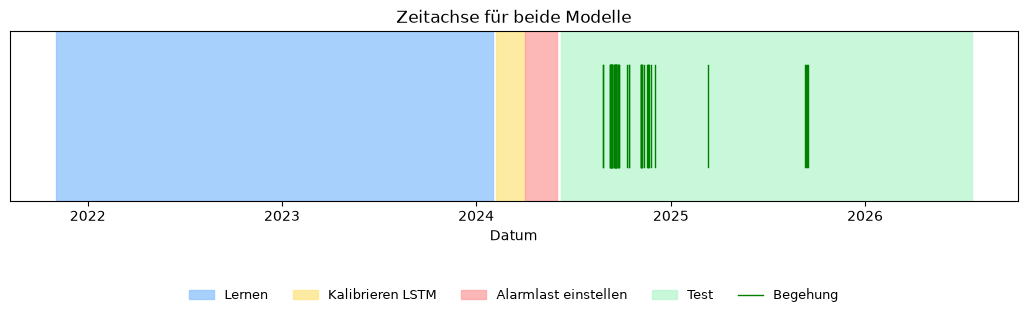

In [5]:
fig, ax = plt.subplots(figsize=(13, 2.2))
abschnitte = [("Lernen", erste, fv.LERN_ENDE, "#93C5FD"),
              ("Kalibrieren LSTM", fv.VAL_START, fv.WAHL_START, "#FDE68A"),
              ("Alarmlast einstellen", fv.WAHL_START, fv.VAL_ENDE, "#FCA5A5"),
              ("Test", fv.TEST_START, letzte, "#BBF7D0")]
for name, von, bis, farbe in abschnitte:
    ax.axvspan(von, bis, color=farbe, alpha=0.8, label=name)
for t in d:
    ax.plot([t, t], [0.2, 0.8], color="green", lw=1)
ax.plot([], [], color="green", lw=1, label="Begehung")
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_title("Zeitachse für beide Modelle")
ax.set_xlabel("Datum")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=5, frameon=False, fontsize=9)
fv.speichere(fig, "00_zeitachse")
plt.show()

## 5 Beide Modelle neu lernen

`fv.waechter_bauen` lernt die Kennlinien des Monitoring-Modells und das Prognose-LSTM auf denselben Tagen, mit frühem Stoppen nur auf der Kalibrierzeit. Danach bekommen alle Wächter dieselbe Alarmlast, und die Gegenproben aus 2.4 kommen dazu. Die Startwerte sind fest (Seed 0), ein neuer Lauf ergibt also dieselben Gewichte. Mit `SELBST_TRAINIEREN = False` im Setup in Abschnitt 3 hält das Notebook hier an. Die Ergebnisse stehen in den gespeicherten Ausgaben.

In [6]:
#Ab hier wird neu gelernt
if not SELBST_TRAINIEREN:
    raise RuntimeError("Angehalten: Ab hier lernt das Notebook alle Modelle neu "
                       "(mit Grafikkarte gut 20 Minuten, ohne rund 5 Stunden). "
                       "Die Ergebnisse stehen in den gespeicherten Ausgaben darunter. "
                       "Zum Neurechnen oben SELBST_TRAINIEREN = True setzen.")

In [7]:
w = fv.waechter_bauen(e)
print("Monitoring-Modell, Referenzstatus:", w["ref"]["status"].value_counts().to_dict())
print("LSTM: gelernt auf", len(w["lstm"]["lern_stationen"]), "Stationen,", w["lstm"]["lern_ziele"], "Lerntage und",
      w["lstm"]["val_ziele"], "Prüftage; kalibriert:", len(w["kal"]), "Stationen")
w = fv.nv_hinzufuegen(w, e)
w = fv.nur_begangene_hinzufuegen(w, e)
print("LSTM mit fester Referenz:", w["nv"]["stationen"], "Stationen,", w["nv"]["lern_tage"], "Referenz-Heiztage,",
      w["nv"]["pruef_tage"], "Prüftage")
print("Prognose-LSTM nur begangene:", len(w["beg"]["stationen"]), "Lernstationen")

Prognose-LSTM: 143 Runden, bester Validierungsfehler 0.1040, 27 s


Monitoring-Modell, Referenzstatus: {'ok': 86, 'zu wenige Referenztage': 6, 'keine Tage nach der Referenz': 1}
LSTM: gelernt auf 87 Stationen, 20510 Lerntage und 8599 Prüftage; kalibriert: 86 Stationen


LSTM mit fester Referenz: 65 Runden, bester Validierungsfehler 0.9982, 4 s


Prognose-LSTM: 104 Runden, bester Validierungsfehler 0.1072, 11 s


LSTM mit fester Referenz: 86 Stationen, 26546 Referenz-Heiztage, 4531 Prüftage
Prognose-LSTM nur begangene: 54 Lernstationen


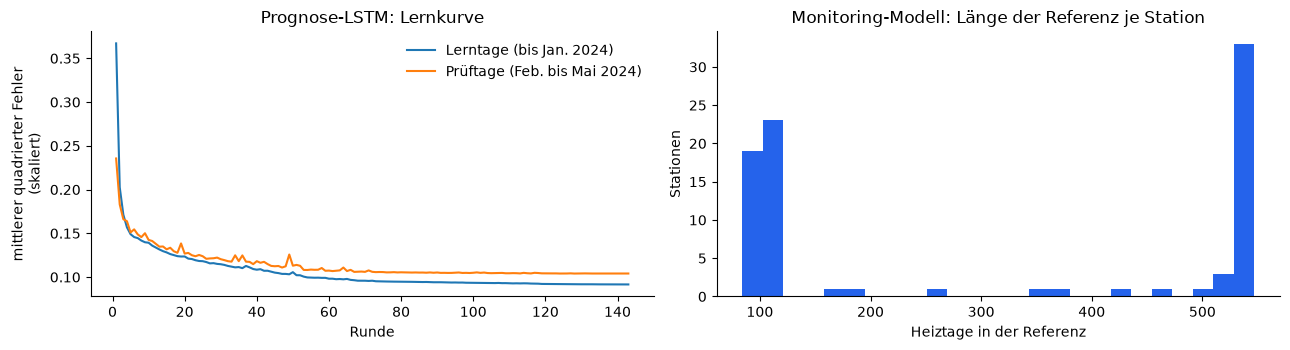

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
k = w["lstm"]["lernkurve"]
ax[0].plot(k["runde"], k["lernen"], label="Lerntage (bis Jan. 2024)")
ax[0].plot(k["runde"], k["validierung"], label="Prüftage (Feb. bis Mai 2024)")
ax[0].set_xlabel("Runde")
ax[0].set_ylabel("mittlerer quadrierter Fehler\n(skaliert)")
ax[0].set_title("Prognose-LSTM: Lernkurve")
ax[0].legend(frameon=False)
r = w["ref"]
ax[1].hist(r.loc[r["status"] == "ok", "ref_tage"], bins=25, color=fv.FARBE_MONITORING)
ax[1].set_xlabel("Heiztage in der Referenz")
ax[1].set_ylabel("Stationen")
ax[1].set_title("Monitoring-Modell: Länge der Referenz je Station")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fv.speichere(fig, "01_lernen")
plt.show()

Das Monitoring-Modell gibt mit h = 5 im April und Mai 2024 eine bestimmte Zahl an Alarmen. Alle anderen Wächter sollen gleich viele bekommen, denn wer öfter alarmiert, trifft automatisch öfter. Gesucht wird deshalb je Regel der Wert, der dieser Zahl am nächsten kommt.

In [9]:
print("Ziel:", w["ziel_alarme"], "Alarme auf", len(w["wahltage"]), "gemeinsamen Stationstagen")
pd.DataFrame([{"Wächter": fv.WAECHTER[k], "Regel": r, "gewählter Wert": v} for k, (r, v) in w["einstellung"].items()])

Ziel: 31 Alarme auf 2184 gemeinsamen Stationstagen


,Wächter,Regel,gewählter Wert
0,Monitoring-Modell (Kennlinie + CUSUM),cusum,5.00
1,LSTM-Modell + Schwelle,schwelle,2.75
2,LSTM-Modell + CUSUM,cusum,10.00
3,Wochenmittel + Schwelle (ohne Lernen),schwelle,3.00
4,Wochenmittel + CUSUM (ohne Lernen),cusum,10.00
5,LSTM mit fester Referenz (gebaut wie der Wächt...,cusum,15.00
6,"LSTM-Modell + CUSUM, nur begangene Stationen g...",cusum,10.00


In [10]:
last = fv.arbeitslast(w)
last.round(2)

,Wächter,Regel,Einstellung,Einstellzeit (Apr–Mai 2024),Test (ab Juni 2024)
0,Monitoring-Modell (Kennlinie + CUSUM),cusum,5.00,5.18,4.34
1,LSTM-Modell + Schwelle,schwelle,2.75,5.52,6.04
2,LSTM-Modell + CUSUM,cusum,10.00,5.52,3.40
3,Wochenmittel + Schwelle (ohne Lernen),schwelle,3.00,6.36,6.15
4,Wochenmittel + CUSUM (ohne Lernen),cusum,10.00,3.51,6.37
5,LSTM mit fester Referenz (gebaut wie der Wächt...,cusum,15.00,5.18,2.66
6,"LSTM-Modell + CUSUM, nur begangene Stationen g...",cusum,10.00,5.18,3.34


In der Einstellzeit liegen alle Wächter bei ähnlich vielen Alarmen je Station und Jahr, im Test weichen sie ab (2,7 bis 6,4). Deshalb zeigen die Tests immer auch die Kontrollquote und Kurven über alle Einstellungen, damit kein Modell nur durch mehr Alarme gewinnt.

## 6 Test A: Merkt das Modell, wenn sich eine Station verändert?

Nach einer Begehung sollte die Station besser laufen. Die Frage ist, ob der Wächter das meldet. Gezählt wird ein Alarm von 7 Tagen vor bis 60 Tage nach dem Termin, mit der Prüfung aus Notebook 18 (`pruefstand.trefferpruefung`). Dasselbe Fenster an Vergleichsstationen ohne Begehung ergibt die Kontrollquote. Getrennt wird nach Richtung wie in Notebook 21, und es zählen nur Heiztage, die alle Wächter beobachten. Ein Alarm nach der Begehung zeigt die Wirkung der Maßnahme, keine Vorhersage des Fehlers.

In [11]:
A, einzel_A = fv.test_begehungen(w, termine)
A_besser = A[A["Richtung"] == "besser"]
A[["Wächter", "Richtung", "Fälle", "bemerkt", "Quote", "Kontrollquote", "Hebel", "p (einseitig)"]].round(3)

,Wächter,Richtung,Fälle,bemerkt,Quote,Kontrollquote,Hebel,p (einseitig)
0,Monitoring-Modell (Kennlinie + CUSUM),besser,43,18,0.419,0.237,1.766,0.006
1,Monitoring-Modell (Kennlinie + CUSUM),alle,43,23,0.535,0.459,1.166,0.198
2,Monitoring-Modell (Kennlinie + CUSUM),schlechter,43,10,0.233,0.275,0.845,0.784
3,LSTM-Modell + Schwelle,besser,43,10,0.233,0.256,0.908,0.694
4,LSTM-Modell + Schwelle,alle,43,19,0.442,0.472,0.936,0.708
5,LSTM-Modell + Schwelle,schlechter,43,11,0.256,0.310,0.824,0.826
6,LSTM-Modell + CUSUM,besser,43,10,0.233,0.263,0.884,0.729
7,LSTM-Modell + CUSUM,alle,43,17,0.395,0.435,0.909,0.749
8,LSTM-Modell + CUSUM,schlechter,43,9,0.209,0.242,0.865,0.746
9,Wochenmittel + Schwelle (ohne Lernen),besser,43,14,0.326,0.262,1.244,0.215


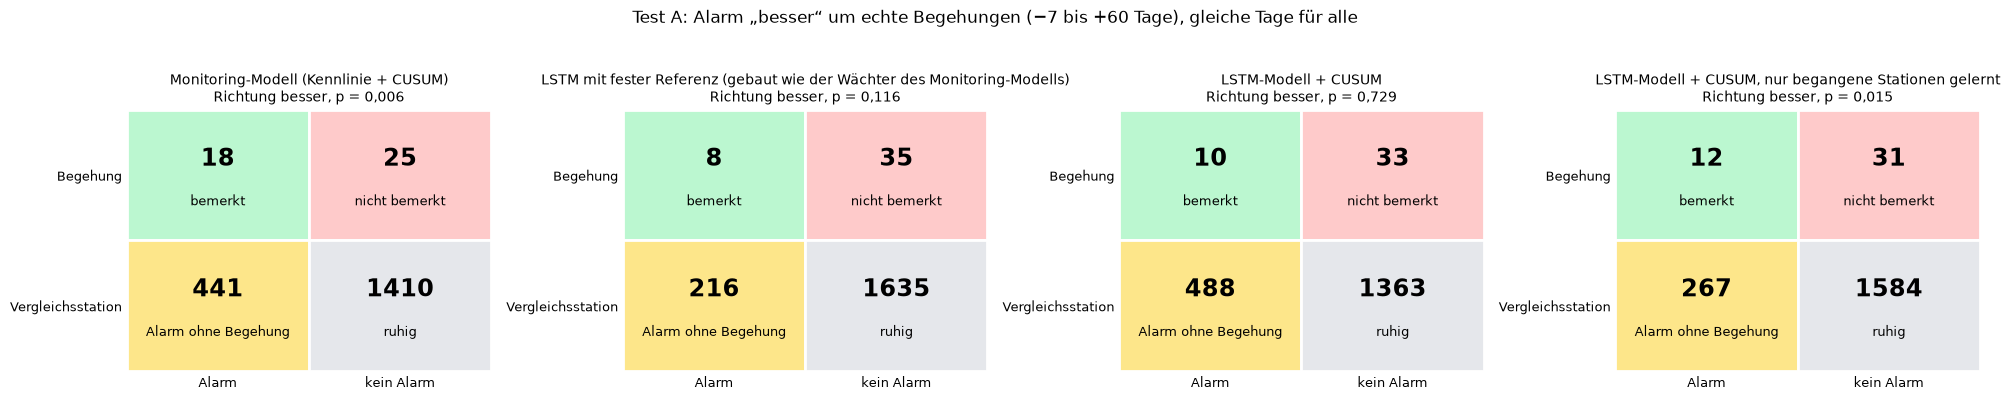

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, key in zip(axes, ["monitoring", "nv", "lstm_c", "lstm_beg"]):
    z = A_besser[A_besser["key"] == key].iloc[0]
    fv.zeichne_vierfeld(ax, z, f"{fv.WAECHTER[key]}\nRichtung besser, p = {z['p (einseitig)']:.3f}".replace(".", ","),
                        zeile_ja="Begehung", zeile_nein="Vergleichsstation",
                        spalte_ja="Alarm", spalte_nein="kein Alarm",
                        woerter=("bemerkt", "nicht bemerkt", "Alarm ohne Begehung", "ruhig"),
                        schluessel=("Begehung, Alarm", "Begehung, kein Alarm", "Kontrolle, Alarm", "Kontrolle, kein Alarm"))
fig.suptitle("Test A: Alarm „besser“ um echte Begehungen (−7 bis +60 Tage), gleiche Tage für alle", y=1.04)
fig.tight_layout()
fv.speichere(fig, "02_testA_konfusion")
plt.show()

Die Vergleichsfenster überlappen sich und zeigen nur die Grundrate, getestet wird über die Begehungen. Die nächste Tabelle vergleicht dieselben Begehungen Fall für Fall, das Monitoring-Modell gegen die anderen (McNemar-Test).

In [13]:
a_mm = einzel_A[("monitoring", "besser")].set_index(["zaehler", "datum"])["treffer"]
zeilen = []
for key in ["nv", "lstm_s", "lstm_c", "lstm_beg", "wm_s", "wm_c"]:
    b = einzel_A[(key, "besser")].set_index(["zaehler", "datum"])["treffer"].reindex(a_mm.index)
    m = ps.mcnemar(a_mm, b)
    zeilen.append({"gegen": fv.WAECHTER[key], "nur Monitoring-Modell": m["nur A"], "nur der andere": m["nur B"],
                   "beide": m["beide"], "keiner": m["keiner"], "p (McNemar)": round(m["p (McNemar)"], 3)})
pd.DataFrame(zeilen)

,gegen,nur Monitoring-Modell,nur der andere,beide,keiner,p (McNemar)
0,LSTM mit fester Referenz (gebaut wie der Wächt...,12,2,6,23,0.013
1,LSTM-Modell + Schwelle,12,4,6,21,0.077
2,LSTM-Modell + CUSUM,15,7,3,18,0.134
3,"LSTM-Modell + CUSUM, nur begangene Stationen g...",12,6,6,19,0.238
4,Wochenmittel + Schwelle (ohne Lernen),10,6,8,19,0.454
5,Wochenmittel + CUSUM (ohne Lernen),10,7,8,18,0.629


Jeder Punkt ist eine Einstellung. Rechts liegen mehr Alarme im Test, oben mehr Vorsprung, also Quote an Begehungen minus Kontrollquote. Der gewählte Punkt ist umrandet.

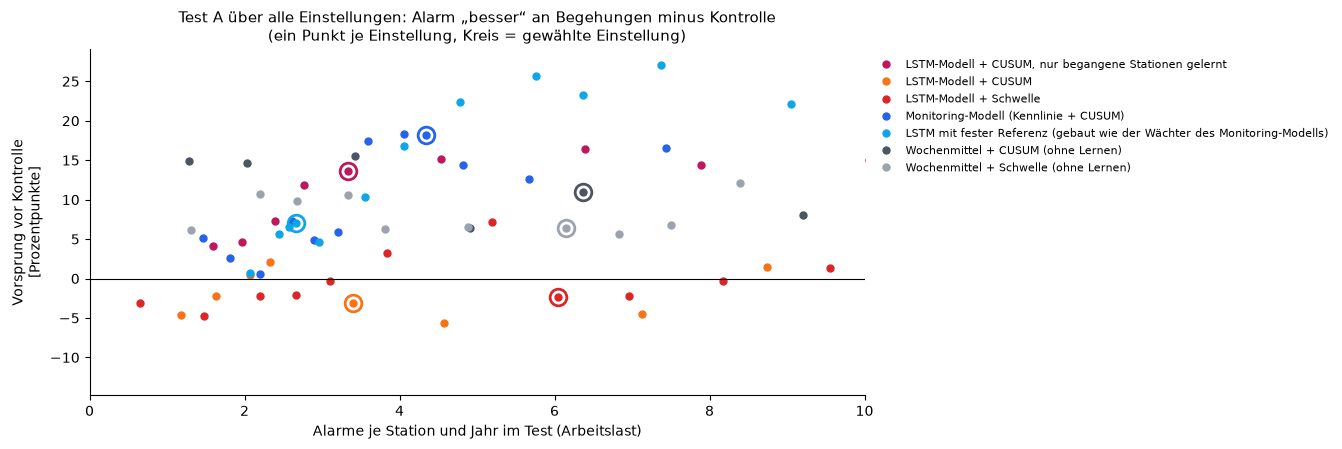

In [14]:
KA = fv.kurve_begehungen(w, termine)
fig, ax = plt.subplots(figsize=(10, 4.5))
farben = {"monitoring": fv.FARBE_MONITORING, "nv": "#0EA5E9", "lstm_s": fv.FARBE_LSTM, "lstm_c": "#F97316",
          "lstm_beg": "#BE185D", "wm_s": "#9CA3AF", "wm_c": "#4B5563"}
for key, g in KA.groupby("key"):
    g = g.sort_values("Arbeitslast")
    ax.plot(g["Arbeitslast"], 100 * g["Vorsprung"], "o", ms=5, color=farben[key], label=fv.WAECHTER[key])
    s = g[g["gewählt"]]
    ax.plot(s["Arbeitslast"], 100 * s["Vorsprung"], "o", ms=12, mfc="none", mec=farben[key], mew=2)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlim(0, 10)
ax.set_xlabel("Alarme je Station und Jahr im Test (Arbeitslast)")
ax.set_ylabel("Vorsprung vor Kontrolle\n[Prozentpunkte]")
ax.set_title("Test A über alle Einstellungen: Alarm „besser“ an Begehungen minus Kontrolle\n(ein Punkt je Einstellung, Kreis = gewählte Einstellung)", fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.spines[["top", "right"]].set_visible(False)
fv.speichere(fig, "03_testA_kurve")
plt.show()

Das Monitoring-Modell bemerkt die Wirkung der Begehungen am deutlichsten. Es meldet bei 18 von 43 Begehungen „besser“, an Vergleichsstationen sind es 24 % (p = 0,006). Das Prognose-LSTM auf allen Stationen liegt bei jeder Einstellung auf Höhe der Kontrolle (10 von 43 gegen 26 %). Fall für Fall ist der Vorsprung des Monitoring-Modells aber nicht gesichert, 12 zu 4 gegen das LSTM mit Schwelle (p = 0,08) und 15 zu 7 gegen das LSTM mit CUSUM (p = 0,13). Das LSTM mit fester Referenz ist bei der gewählten Einstellung zu streng (8 von 43 gegen 12 %), bei gleicher Alarmmenge aber fast gleichauf (Abschnitt 7.1).

Das Prognose-LSTM „nur begangene“ sieht besser aus, mit 12 von 43 gegen 14 % (p = 0,02). Bei sieben Wächtern und drei Richtungen sieht aber leicht einer zufällig gut aus, und im Sommer ist diese Variante schwächer (Test B). Sie bleibt deshalb Gegenprobe.

### 6.1 Gegenprobe: beide Wächter „wie gebaut“

Hier gilt die eigene Regel des Monitoring-Modells, nach der die Referenz das erste Jahr der Station ist und 14 Tage vor einer früheren Begehung endet. Das LSTM ist das Paket aus Notebook 28 (in Betrieb seit 24.10.2026), gelernt bis Juni 2024, mit der Regel Schwelle z ≥ 4. Mit diesen Varianten hat Notebook 34 gerechnet.

In [15]:
ref_g = fv.monitoring_referenz(w["mt"], termine, lern_ende=None)
mod_g, _ = tm.modelle(w["mt"], ref_g)
verl_g = fv.monitoring_verlauf(w["mt"], ref_g, mod_g)
al_g = fv.monitoring_alarme(verl_g)
#das Paket mit dem Code aus Notebook 28, nicht die gerade aktive Version
nb30 = [v for v in mp.versionen("prognose_lstm")
        if any(k in mp.lade_paket("prognose_lstm", v, pruefen=False).meta.get("quelle", "")
               for k in ("28_prognose", "30_prognose", "21_prognose"))]
alt_lstm = pw.lade(nb30[-1])
print("LSTM-Paket wie gebaut:", alt_lstm["paket"].version, "| Regel:", alt_lstm["parameter"].get("alarmregel"),
      alt_lstm["parameter"].get("schwelle"))
tab_alt = pw.anwenden(alt_lstm, e["stunden"])
tab_alt = tab_alt[tab_alt["status"] == "überwacht"]
al_alt = fv._alarmzeilen(tab_alt, tab_alt["alarm"].to_numpy())
al_alt["bewertung"] = np.where(al_alt["richtung"] > 0, "schlechter", "besser")
beob_g = fv.gemeinsame_tage(fv.monitoring_beobachtet(verl_g), fv.lstm_beobachtet(tab_alt))
A_g, einzel_g = fv.test_begehungen(w, termine, alarme={"monitoring (wie gebaut)": al_g, "lstm (Paket NB 28)": al_alt},
                                   tage=beob_g)
A_g[["Wächter", "Richtung", "Fälle", "bemerkt", "Quote", "Kontrollquote", "p (einseitig)"]].round(3)

LSTM-Paket wie gebaut: 2026-10-24_132552 | Regel: schwelle 4.0


,Wächter,Richtung,Fälle,bemerkt,Quote,Kontrollquote,p (einseitig)
0,monitoring (wie gebaut),besser,43,25,0.581,0.217,0.000
1,monitoring (wie gebaut),alle,43,29,0.674,0.486,0.010
2,monitoring (wie gebaut),schlechter,43,14,0.326,0.312,0.483
3,lstm (Paket NB 28),besser,43,7,0.163,0.078,0.048
4,lstm (Paket NB 28),alle,43,12,0.279,0.222,0.233
5,lstm (Paket NB 28),schlechter,43,9,0.209,0.177,0.349


In [16]:
t = einzel_g[("monitoring (wie gebaut)", "alle")].copy()
t["Referenz endet direkt vor dieser Begehung"] = [
    ref_g.at[z, "ende_grund"] == "vor Begehung" and 0 <= (dt - ref_g.at[z, "ref_ende"]).days <= 30
    for z, dt in zip(t["zaehler"], t["datum"])]
t.groupby("Referenz endet direkt vor dieser Begehung").agg(Begehungen=("treffer", "size"),
    bemerkt=("treffer", "sum"), Kontrollquote=("kontrollquote", "mean")).round(2)

,Begehungen,bemerkt,Kontrollquote
Referenz endet direkt vor dieser Begehung,,,
False,25,15,0.47
True,18,14,0.51


„Wie gebaut“ bemerkt das Monitoring-Modell mehr, 25 von 43 gegen 22 % (p < 0,001). Ein Teil davon kommt aus der Referenzregel: Bei 18 Begehungen endet die Referenz kurz vorher, und davon sind 14 bemerkt, von den übrigen 25 nur 15. Für die Erfolgskontrolle im Betrieb ist das gewollt, für einen fairen Vergleich nicht.

### 6.2 Gegenprobe: nur begangene Stationen als Vergleich

Das Prognose-LSTM „nur begangene“ kennt kaum eine Vergleichsstation. Deshalb zählen hier für alle Wächter nur begangene Stationen ohne eigene Begehung im Fenster als Vergleich.

In [17]:
nur_beg = list(e["labels"].index)
gt_ = w["gemeinsam"][w["gemeinsam"]["datum"] >= fv.TEST_START]
zeilen = []
for key, a in w["alarme"].items():
    a = fv.nur_tage(a, gt_)
    for richt in ("besser", "alle"):
        aa = a if richt == "alle" else a[a["bewertung"] == richt]
        b = ps.bilanz(ps.trefferpruefung(aa, gt_, fv.begehungsfaelle(termine), termine, stationen=nur_beg))
        zeilen.append({"Wächter": fv.WAECHTER[key], "Richtung": richt, "Fälle": b["Fälle"], "bemerkt": b["Treffer"],
                       "Kontrollquote": b["Kontrollquote"], "p (einseitig)": b["p (einseitig)"]})
pd.DataFrame(zeilen).round(3)

,Wächter,Richtung,Fälle,bemerkt,Kontrollquote,p (einseitig)
0,Monitoring-Modell (Kennlinie + CUSUM),besser,43,18,0.337,0.167
1,Monitoring-Modell (Kennlinie + CUSUM),alle,43,23,0.529,0.531
2,LSTM-Modell + Schwelle,besser,43,10,0.301,0.875
3,LSTM-Modell + Schwelle,alle,43,19,0.450,0.602
4,LSTM-Modell + CUSUM,besser,43,10,0.448,0.999
5,LSTM-Modell + CUSUM,alle,43,17,0.505,0.945
6,Wochenmittel + Schwelle (ohne Lernen),besser,43,14,0.244,0.143
7,Wochenmittel + Schwelle (ohne Lernen),alle,43,22,0.555,0.766
8,Wochenmittel + CUSUM (ohne Lernen),besser,43,15,0.229,0.050
9,Wochenmittel + CUSUM (ohne Lernen),alle,43,18,0.389,0.402


Mit nur begangenen Stationen als Vergleich schrumpft der Vorsprung des Monitoring-Modells (18 von 43 gegen 34 %, p = 0,17). Diese Stationen hatten selbst Maßnahmen, und das Monitoring-Modell meldet September-Begehungen oft erst im Oktober oder November, also im Fenster späterer Begehungen. Maßgeblich bleibt deshalb die Hauptprüfung. Verschlechterungen gibt es an Begehungen nicht öfter als sonst, beide Richtungen zusammen trennen nicht (23 von 43 gegen 46 %). Der Wächter zeigt also die Wirkung einer Maßnahme, keine Vorhersage eines Fehlers, wie schon in Notebook 21. Fürs Dashboard heißt das: Der Tagesmonitor ist der Wächter für die Heizperiode und für die Erfolgskontrolle nach einer Maßnahme.

## 7 Test B: Findet das Modell eingebaute Fehler?

Bei echten Fehlern ist der Beginn nie bekannt. Deshalb wird ein Fehler mit bekanntem Beginn 30 Tage lang in echte Stundenwerte aus Notebook 00 geschrieben, je Station und Jahreszeit ab einem zufälligen Starttag mit genug Messwerten und ohne Begehung in der Nähe. Alle Spalten bleiben stimmig, auch Energie- und Volumenzähler. So lässt sich anders als in Notebook 28 und 34 auch der Wächter des Monitoring-Modells prüfen.

| eingebauter Fehler | was passiert |
|---|---|
| Dauerdurchfluss 50 / 150 l/h | zusätzliches Wasser mit Vorlauftemperatur, Rücklauf mischt sich warm |
| Rücklauf +5 K | gleiche Leistung bei 5 K kleinerer Spreizung |
| schleichend +5 K in 30 Tagen | wie oben, langsam ansteigend (z. B. Verschmutzung) |
| Regelhysterese 6 h | 3 h 30 % mehr, 3 h 30 % weniger Durchfluss |
| Fühler hängt | Rücklauffühler bleibt stehen |

Ein Treffer ist ein Alarm in 14 Tagen ab Fehlerbeginn, beim schleichenden Fehler in 30 Tagen. Dasselbe Fenster ohne Fehler ergibt die Fehlalarmquote. Hier ist die Wahrheit bekannt.

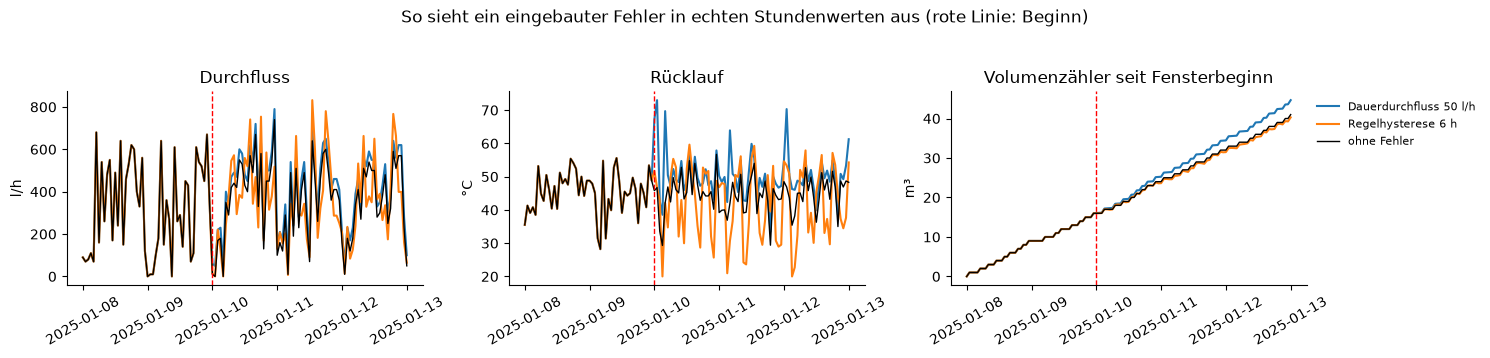

In [18]:
beispiel = e["serien"][next(m for m in w["kal"].index if e["serien"][m].loc["2025-01-05":"2025-01-15", "flow"].notna().sum() > 200)]
start = pd.Timestamp("2025-01-10")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4), sharex=True)
for art, (typ, staerke) in [("Dauerdurchfluss 50 l/h", fv.STOERUNGEN["Dauerdurchfluss 50 l/h"]),
                            ("Regelhysterese 6 h", fv.STOERUNGEN["Regelhysterese 6 h"])]:
    g = fv.stoerung_einrechnen(beispiel, start, typ, staerke, tage=5)
    fenster = g.loc[start - pd.Timedelta(days=2): start + pd.Timedelta(days=3)]
    ax[0].plot(fenster.index, fenster["flow"], label=art)
    ax[1].plot(fenster.index, fenster["rt"], label=art)
    ax[2].plot(fenster.index, fenster["volume"] - fenster["volume"].iloc[0], label=art)
roh = beispiel.loc[start - pd.Timedelta(days=2): start + pd.Timedelta(days=3)]
ax[0].plot(roh.index, roh["flow"], color="black", lw=1, label="ohne Fehler")
ax[1].plot(roh.index, roh["rt"], color="black", lw=1, label="ohne Fehler")
ax[2].plot(roh.index, roh["volume"] - roh["volume"].iloc[0], color="black", lw=1, label="ohne Fehler")
for a, t, y in zip(ax, ["Durchfluss", "Rücklauf", "Volumenzähler seit Fensterbeginn"], ["l/h", "°C", "m³"]):
    a.set_title(t)
    a.set_ylabel(y)
    a.axvline(start, color="red", ls="--", lw=1)
    a.spines[["top", "right"]].set_visible(False)
    a.tick_params(axis="x", labelrotation=30)
ax[2].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.suptitle("So sieht ein eingebauter Fehler in echten Stundenwerten aus (rote Linie: Beginn)", y=1.04)
fig.tight_layout()
plt.show()

In [19]:
ST = fv.stoerungen_rechnen(w, e)
SA = fv.stoerungen_auswerten(ST, w)
print(ST["faelle"].groupby("saison").size().rename("Stationen je Jahreszeit").to_dict())
SA.groupby(["saison", "Wächter"])["bewertbar"].mean().unstack().round(2)

25/157 Fälle, 10 s


50/157 Fälle, 20 s


75/157 Fälle, 30 s


100/157 Fälle, 40 s


125/157 Fälle, 50 s


150/157 Fälle, 60 s


{'Sommer': 78, 'Winter': 79}


Wächter,LSTM mit fester Referenz (gebaut wie der Wächter des Monitoring-Modells),LSTM-Modell + CUSUM,"LSTM-Modell + CUSUM, nur begangene Stationen gelernt",LSTM-Modell + Schwelle,Monitoring-Modell (Kennlinie + CUSUM),Wochenmittel + CUSUM (ohne Lernen),Wochenmittel + Schwelle (ohne Lernen)
saison,,,,,,,
Sommer,0.00,1.00,1.00,1.00,0.00,1.00,1.00
Winter,0.99,0.99,0.99,0.99,0.99,0.99,0.99


Im Sommer kann der Wächter des Monitoring-Modells nicht bewerten, weil er nur an Heiztagen rechnet, dort gibt es nur LSTM oder Wochenmittel. Die nächsten Tabellen zeigen Trefferquote und Tage bis zum Alarm bei den gewählten Einstellungen, die Zeile „ohne Fehler“ ist die Fehlalarmquote.

In [20]:
B = (SA[SA["bewertbar"]].groupby(["saison", "art", "Wächter"])
     .agg(Fälle=("alarm", "size"), Trefferquote=("alarm", "mean"), Tage_bis_Alarm=("tage_bis_alarm", "median"))
     .reset_index())
B.pivot_table(index=["saison", "art"], columns="Wächter", values="Trefferquote").round(2)

Wächter                              LSTM mit fester Referenz (gebaut wie der Wächter des Monitoring-Modells)  LSTM-Modell + CUSUM  LSTM-Modell + CUSUM, nur begangene Stationen gelernt  LSTM-Modell + Schwelle  \
saison art                                                                                                                                                                                                         
Sommer Dauerdurchfluss 150 l/h                                                     NaN                                        0.78                                               0.68                       0.81   
       Dauerdurchfluss 50 l/h                                                      NaN                                        0.44                                               0.45                       0.46   
       Fühler hängt                                                                NaN                                        0.36                                               0.32                       0.35   
       Regelhysterese 6 h                                                          NaN                                        0.08                                               0.08                       0.13   
       Rücklauf +5 K                                                               NaN                                        0.12                                               0.14                       0.26   
       ohne Fehler                                                                 NaN                                        0.04                                               0.05                       0.10   
       schleichend +5 K in 30 Tagen                                                NaN                                        0.18                                               0.17                       0.26   
Winter Dauerdurchfluss 150 l/h                                                    0.65                                        0.69                                               0.67                       0.73   
       Dauerdurchfluss 50 l/h                                                     0.42                                        0.46                                               0.44                       0.59   
       Fühler hängt                                                               0.37                                        0.27                                               0.33                       0.36   
       Regelhysterese 6 h                                                         0.05                                        0.10                                               0.12                       0.24   
       Rücklauf +5 K                                                              0.38                                        0.24                                               0.23                       0.42   
       ohne Fehler                                                                0.05                                        0.03                                               0.08                       0.18   
       schleichend +5 K in 30 Tagen                                               0.37                                        0.18                                               0.28                       0.44   

Wächter                              Monitoring-Modell (Kennlinie + CUSUM)  Wochenmittel + CUSUM (ohne Lernen)  Wochenmittel + Schwelle (ohne Lernen)  
saison art                                                                                                                                             
Sommer Dauerdurchfluss 150 l/h                                         NaN                                0.85                                   0.77  
       Dauerdurchfluss 50 l/h                                          NaN                                0.56                                   0.49  

In [21]:
B.pivot_table(index=["saison", "art"], columns="Wächter", values="Tage_bis_Alarm").round(1)

Wächter                              LSTM mit fester Referenz (gebaut wie der Wächter des Monitoring-Modells)  LSTM-Modell + CUSUM  LSTM-Modell + CUSUM, nur begangene Stationen gelernt  LSTM-Modell + Schwelle  \
saison art                                                                                                                                                                                                         
Sommer Dauerdurchfluss 150 l/h                                                     NaN                                         2.0                                                1.0                        1.0   
       Dauerdurchfluss 50 l/h                                                      NaN                                         3.5                                                4.0                        1.0   
       Fühler hängt                                                                NaN                                         4.0                                                4.0                        1.0   
       Regelhysterese 6 h                                                          NaN                                         9.0                                                7.0                        2.0   
       Rücklauf +5 K                                                               NaN                                         6.0                                                7.0                        4.0   
       ohne Fehler                                                                 NaN                                        11.0                                                7.5                        4.0   
       schleichend +5 K in 30 Tagen                                                NaN                                        22.0                                               18.0                       11.0   
Winter Dauerdurchfluss 150 l/h                                                     3.0                                         0.5                                                0.5                        1.0   
       Dauerdurchfluss 50 l/h                                                      6.0                                         1.0                                                2.5                        1.0   
       Fühler hängt                                                                4.0                                         3.0                                                7.0                        2.0   
       Regelhysterese 6 h                                                          4.5                                         9.0                                                8.0                        4.0   
       Rücklauf +5 K                                                               6.5                                         4.0                                                3.0                        2.0   
       ohne Fehler                                                                 4.5                                         7.5                                                4.0                        8.0   
       schleichend +5 K in 30 Tagen                                               22.0                                        23.0                                               18.0                       13.0   

Wächter                              Monitoring-Modell (Kennlinie + CUSUM)  Wochenmittel + CUSUM (ohne Lernen)  Wochenmittel + Schwelle (ohne Lernen)  
saison art                                                                                                                                             
Sommer Dauerdurchfluss 150 l/h                                         NaN                                 1.0                                    1.0  
       Dauerdurchfluss 50 l/h                                          NaN                                 2.0                                    1.0  

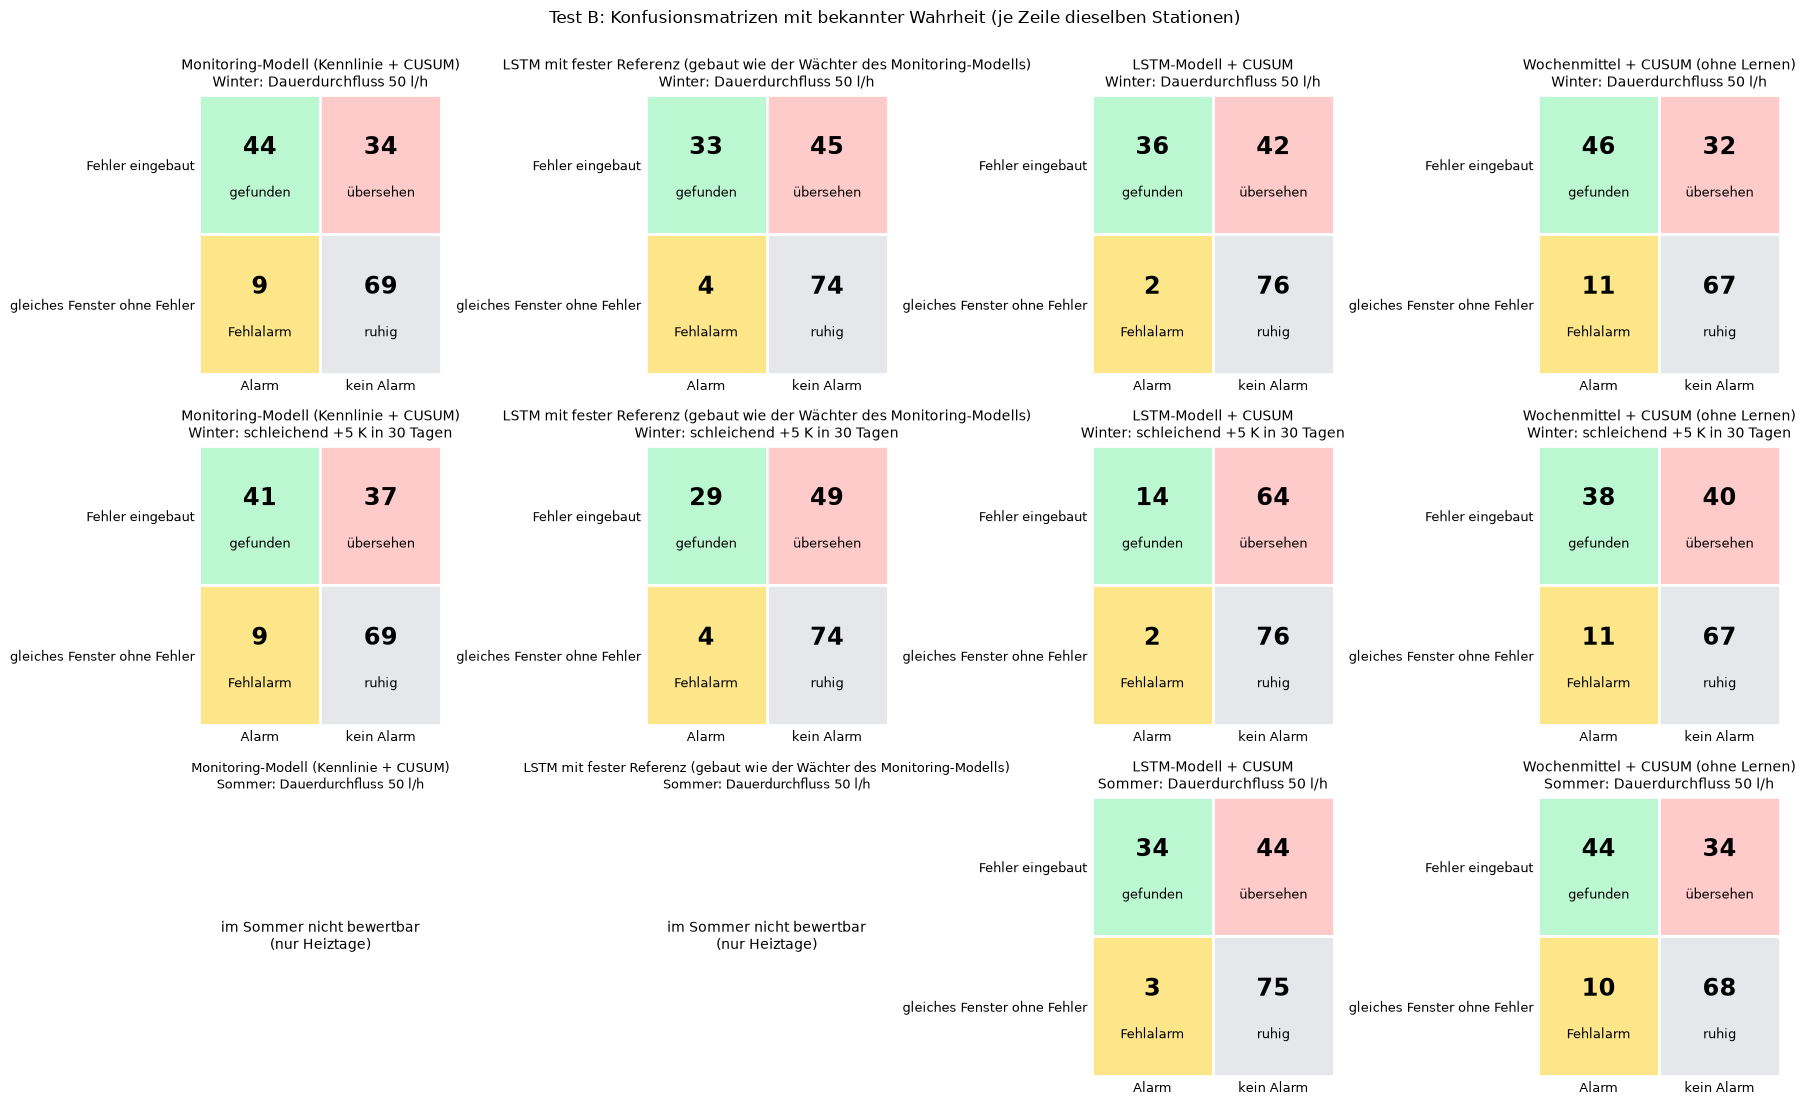

In [22]:
def vierfeld_stoerung(sa, key, saison, art):
    t = sa[(sa["key"] == key) & (sa["saison"] == saison) & sa["bewertbar"]]
    mit = t[t["art"] == art].set_index("zaehler")["alarm"]
    ohne = t[t["art"] == "ohne Fehler"].set_index("zaehler")["alarm"].reindex(mit.index).dropna().astype(bool)
    mit = mit.reindex(ohne.index)
    return {"gefunden": int(mit.sum()), "übersehen": int((~mit).sum()),
            "Fehlalarm": int(ohne.sum()), "ruhig": int((~ohne).sum())}

faelle_bild = [("Winter", "Dauerdurchfluss 50 l/h"), ("Winter", "schleichend +5 K in 30 Tagen"),
               ("Sommer", "Dauerdurchfluss 50 l/h")]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for i, (saison, art) in enumerate(faelle_bild):
    for j, key in enumerate(["monitoring", "nv", "lstm_c", "wm_c"]):
        ax = axes[i, j]
        if saison == "Sommer" and key in ("monitoring", "nv"):
            ax.text(0.5, 0.5, "im Sommer nicht bewertbar\n(nur Heiztage)", ha="center", va="center")
            ax.axis("off")
            ax.set_title(f"{fv.WAECHTER[key]}\n{saison}: {art}", fontsize=9)
            continue
        fv.zeichne_vierfeld(ax, vierfeld_stoerung(SA, key, saison, art), f"{fv.WAECHTER[key]}\n{saison}: {art}",
                            zeile_ja="Fehler eingebaut", zeile_nein="gleiches Fenster ohne Fehler",
                            spalte_ja="Alarm", spalte_nein="kein Alarm",
                            woerter=("gefunden", "übersehen", "Fehlalarm", "ruhig"))
fig.suptitle("Test B: Konfusionsmatrizen mit bekannter Wahrheit (je Zeile dieselben Stationen)", y=1.0)
fig.tight_layout()
fv.speichere(fig, "04_testB_konfusion")
plt.show()

Mehr Alarme heißen mehr Treffer und mehr Fehlalarme. Das Bild zeigt jede Einstellung als Punkt, oben links ist besser. Darunter steht die Trefferquote bei höchstens 10 % bzw. 5 % Fehlalarmen, abgelesen auf dem Test, nur zum Vergleich und nicht zum Einstellen.

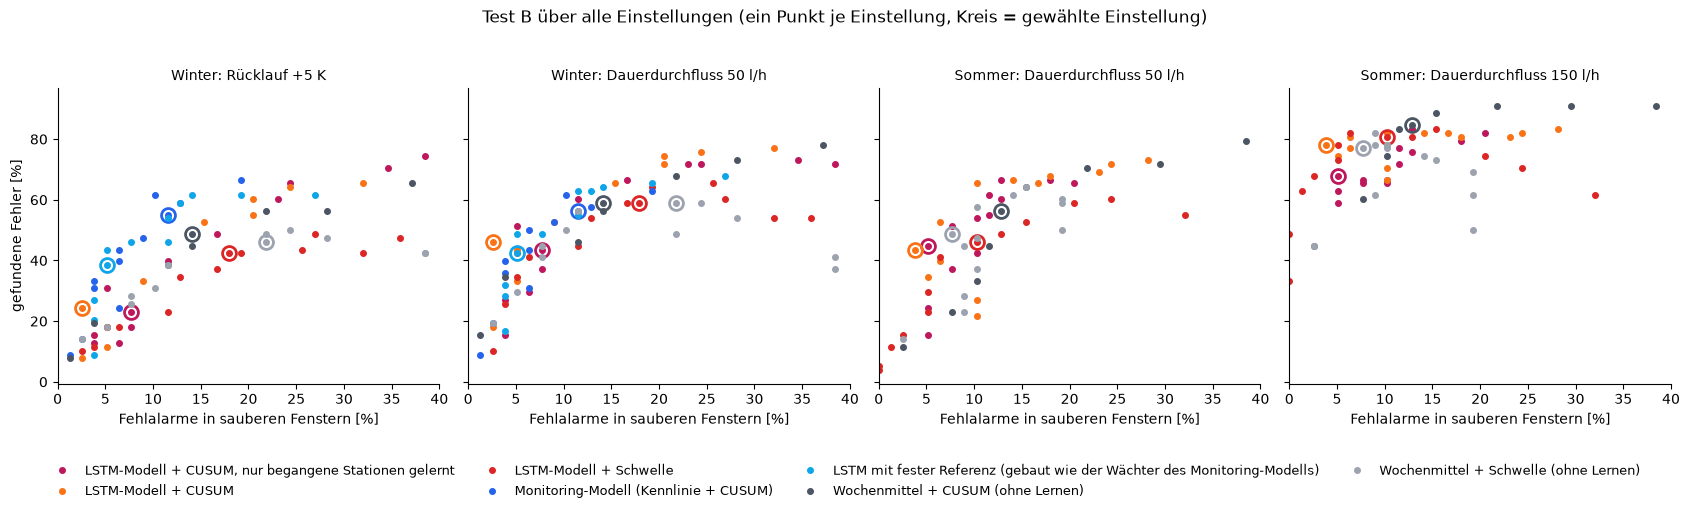

In [23]:
SK = fv.stoerungen_kurve(ST, w)
zeigen = [("Winter", "Rücklauf +5 K"), ("Winter", "Dauerdurchfluss 50 l/h"), ("Sommer", "Dauerdurchfluss 50 l/h"),
          ("Sommer", "Dauerdurchfluss 150 l/h")]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, (saison, art) in zip(axes, zeigen):
    for key, g in SK[(SK["saison"] == saison) & (SK["art"] == art)].groupby("key"):
        g = g.sort_values("Fehlalarmquote")
        ax.plot(100 * g["Fehlalarmquote"], 100 * g["Trefferquote"], "o", ms=4, color=farben[key], label=fv.WAECHTER[key])
        s = g[g["gewählt"]]
        ax.plot(100 * s["Fehlalarmquote"], 100 * s["Trefferquote"], "o", ms=10, mfc="none", mec=farben[key], mew=2)
    ax.set_title(f"{saison}: {art}", fontsize=10)
    ax.set_xlabel("Fehlalarme in sauberen Fenstern [%]")
    ax.set_xlim(0, 40)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("gefundene Fehler [%]")
griffe, namen = axes[0].get_legend_handles_labels()
fig.legend(griffe, namen, loc="lower center", bbox_to_anchor=(0.5, -0.16), ncol=4, frameon=False, fontsize=9)
fig.suptitle("Test B über alle Einstellungen (ein Punkt je Einstellung, Kreis = gewählte Einstellung)", y=1.03)
fig.tight_layout()
fv.speichere(fig, "05_testB_kurven")
plt.show()

In [24]:
def bester_bei(g, fa):
    ok = g[g["Fehlalarmquote"] <= fa + 1e-9]
    return ok["Trefferquote"].max() if len(ok) else np.nan

gleich10 = SK.groupby(["saison", "art", "Wächter"]).apply(lambda g: bester_bei(g, 0.10)).unstack("Wächter")
gleich5 = SK.groupby(["saison", "art", "Wächter"]).apply(lambda g: bester_bei(g, 0.05)).unstack("Wächter")
print("Trefferquote bei höchstens 10 % Fehlalarmen")
display(gleich10.round(2))
print("Trefferquote bei höchstens 5 % Fehlalarmen")
gleich5.round(2)

Trefferquote bei höchstens 10 % Fehlalarmen


Wächter                              LSTM mit fester Referenz (gebaut wie der Wächter des Monitoring-Modells)  LSTM-Modell + CUSUM  LSTM-Modell + CUSUM, nur begangene Stationen gelernt  LSTM-Modell + Schwelle  \
saison art                                                                                                                                                                                                         
Sommer Dauerdurchfluss 150 l/h                                                     NaN                                        0.81                                               0.68                       0.82   
       Dauerdurchfluss 50 l/h                                                      NaN                                        0.53                                               0.51                       0.41   
       Fühler hängt                                                                NaN                                        0.36                                               0.33                       0.31   
       Regelhysterese 6 h                                                          NaN                                        0.10                                               0.09                       0.12   
       Rücklauf +5 K                                                               NaN                                        0.24                                               0.14                       0.22   
       schleichend +5 K in 30 Tagen                                                NaN                                        0.24                                               0.19                       0.22   
Winter Dauerdurchfluss 150 l/h                                                    0.74                                        0.73                                               0.72                       0.63   
       Dauerdurchfluss 50 l/h                                                     0.49                                        0.53                                               0.51                       0.41   
       Fühler hängt                                                               0.44                                        0.38                                               0.37                       0.19   
       Regelhysterese 6 h                                                         0.12                                        0.15                                               0.12                       0.06   
       Rücklauf +5 K                                                              0.46                                        0.33                                               0.31                       0.18   
       schleichend +5 K in 30 Tagen                                               0.38                                        0.27                                               0.28                       0.28   

Wächter                              Monitoring-Modell (Kennlinie + CUSUM)  Wochenmittel + CUSUM (ohne Lernen)  Wochenmittel + Schwelle (ohne Lernen)  
saison art                                                                                                                                             
Sommer Dauerdurchfluss 150 l/h                                         NaN                                0.60                                   0.82  
       Dauerdurchfluss 50 l/h                                          NaN                                0.23                                   0.49  
       Fühler hängt                                                    NaN                                0.12                                   0.31  
       Regelhysterese 6 h                                              NaN                                0.08                                   0.12  
       Rücklauf +5 K                                                   NaN                                0.15         

Trefferquote bei höchstens 5 % Fehlalarmen


Wächter                              LSTM mit fester Referenz (gebaut wie der Wächter des Monitoring-Modells)  LSTM-Modell + CUSUM  LSTM-Modell + CUSUM, nur begangene Stationen gelernt  LSTM-Modell + Schwelle  \
saison art                                                                                                                                                                                                         
Sommer Dauerdurchfluss 150 l/h                                                     NaN                                        0.78                                                NaN                       0.68   
       Dauerdurchfluss 50 l/h                                                      NaN                                        0.44                                                NaN                       0.15   
       Fühler hängt                                                                NaN                                        0.36                                                NaN                       0.17   
       Regelhysterese 6 h                                                          NaN                                        0.08                                                NaN                       0.04   
       Rücklauf +5 K                                                               NaN                                        0.12                                                NaN                       0.10   
       schleichend +5 K in 30 Tagen                                                NaN                                        0.18                                                NaN                       0.10   
Winter Dauerdurchfluss 150 l/h                                                    0.63                                        0.69                                               0.45                       0.53   
       Dauerdurchfluss 50 l/h                                                     0.32                                        0.46                                               0.27                       0.26   
       Fühler hängt                                                               0.29                                        0.27                                               0.13                       0.13   
       Regelhysterese 6 h                                                         0.04                                        0.10                                               0.04                       0.05   
       Rücklauf +5 K                                                              0.27                                        0.24                                               0.15                       0.12   
       schleichend +5 K in 30 Tagen                                               0.26                                        0.18                                               0.15                       0.16   

Wächter                              Monitoring-Modell (Kennlinie + CUSUM)  Wochenmittel + CUSUM (ohne Lernen)  Wochenmittel + Schwelle (ohne Lernen)  
saison art                                                                                                                                             
Sommer Dauerdurchfluss 150 l/h                                         NaN                                0.45                                   0.45  
       Dauerdurchfluss 50 l/h                                          NaN                                0.12                                   0.14  
       Fühler hängt                                                    NaN                                0.03                                   0.05  
       Regelhysterese 6 h                                              NaN                                0.03                                   0.03  
       Rücklauf +5 K                                                   NaN                                0.05         

Im Winter findet das Monitoring-Modell bei gleicher Fehlalarmquote am meisten. Bei höchstens 10 % Fehlalarmen erkennt es 47 % der Rücklauffehler von +5 K, das Prognose-LSTM 33 %. Beim schleichenden Fehler sind es 42 gegen 27 %, bei einem hängenden Fühler 46 gegen 38 %. Beim Dauerdurchfluss liegen alle nah beieinander. Das LSTM mit fester Referenz liegt jedes Mal knapp hinter dem Monitoring-Modell.

Im Sommer kann nur das Prognose-LSTM prüfen. Mit CUSUM findet es bei höchstens 5 % Fehlalarmen 78 % der Dauerdurchflüsse von 150 l/h, das Wochenmittel 45 %. Bei 50 l/h sind es 44 gegen 12 bis 14 %. Die Variante „nur begangene“ ist im Sommer schwächer, für warme Tage bleibt also das LSTM auf allen Stationen. Für das LSTM ist CUSUM besser als die Schwelle, mit gleich vielen oder mehr Treffern bei 3 bis 4 % statt 10 bis 18 % Fehlalarmen.

Die Regelhysterese findet keiner (höchstens 15 %), weil alle mit Tagesmitteln rechnen. Dauerdurchfluss wird nach 1 bis 3 Tagen gemeldet, schleichende Fehler nach 2 bis 3 Wochen. Eingebaute Fehler sind allerdings sauberer als echte.

### 7.1 Ist das Monitoring-Modell nur im Vorteil, weil es für den Winter gebaut ist?

Verglichen werden drei Wächter auf denselben Heiztagen: die Kennlinie des Monitoring-Modells, ein LSTM mit derselben Bauweise (feste Referenz) und das Prognose-LSTM. Für Test A zählt ohne gewählte Einstellung der Vorsprung vor der Kontrolle an dem Punkt jeder Kurve, der 4,3 Alarmen je Station und Jahr am nächsten liegt, der Arbeitslast des Monitoring-Modells. Für Test B zählt die Trefferquote im Winter bei höchstens 10 % Fehlalarmen. Dazu kommt die Vorhersagegenauigkeit auf denselben Testtagen.

In [25]:
zeilen = []
for key in ["monitoring", "nv", "lstm_c"]:
    k = KA[KA["key"] == key].copy()
    nah = k.iloc[(k["Arbeitslast"] - 4.34).abs().argmin()]
    z = {"Wächter": fv.WAECHTER[key], "Test A: Arbeitslast": nah["Arbeitslast"], "Test A: Vorsprung [Pp.]": 100 * nah["Vorsprung"]}
    for art in ["Rücklauf +5 K", "schleichend +5 K in 30 Tagen", "Dauerdurchfluss 50 l/h", "Dauerdurchfluss 150 l/h", "Fühler hängt"]:
        z[f"Test B Winter: {art}"] = gleich10.loc[("Winter", art), fv.WAECHTER[key]]
    zeilen.append(z)
vergleich_nv = pd.DataFrame(zeilen).set_index("Wächter")
display(vergleich_nv.round(2).T)
m = w["verlauf"].merge(w["nv"]["verlauf"], on=["meter", "kanal", "datum"], suffixes=("_mm", "_nv"))
m = m[m["datum"] >= fv.TEST_START]
fehler = m.assign(Kennlinie=(m["wert_mm"] - m["erwartung_mm"]).abs(), LSTM_feste_Referenz=(m["wert_nv"] - m["erwartung_nv"]).abs())
print("Mittlerer absoluter Vorhersagefehler im Test (Median über Tage):")
fehler.groupby("kanal")[["Kennlinie", "LSTM_feste_Referenz"]].median().round(3)

Wächter,Monitoring-Modell (Kennlinie + CUSUM),LSTM mit fester Referenz (gebaut wie der Wächter des Monitoring-Modells),LSTM-Modell + CUSUM
Test A: Arbeitslast,4.34,4.06,4.58
Test A: Vorsprung [Pp.],18.15,16.81,-5.64
Test B Winter: Rücklauf +5 K,0.47,0.46,0.33
Test B Winter: schleichend +5 K in 30 Tagen,0.42,0.38,0.27
Test B Winter: Dauerdurchfluss 50 l/h,0.53,0.49,0.53
Test B Winter: Dauerdurchfluss 150 l/h,0.77,0.74,0.73
Test B Winter: Fühler hängt,0.46,0.44,0.38


Mittlerer absoluter Vorhersagefehler im Test (Median über Tage):


,Kennlinie,LSTM_feste_Referenz
kanal,,
kwh_pro_m3,3.621,3.310
log_volumen,0.250,0.236


Beide sind gleich gut. Der Vorsprung vor der Kontrolle liegt bei gut 4 Alarmen je Station und Jahr bei 18 Prozentpunkten für das Monitoring-Modell und 17 für das LSTM mit fester Referenz, und im Winter liegen die eingebauten Fehler 1 bis 4 Prozentpunkte auseinander. Das Netz sagt etwas genauer voraus (3,31 gegen 3,62 kWh/m³ bei der Abkühlung), daraus folgen aber keine besseren Alarme. Das Prognose-LSTM liegt bei gleicher Last unter der Kontrolle (−6 Prozentpunkte).

Der Vorteil des Monitoring-Modells kommt also von der festen Referenz, die bleibende Veränderungen nicht „vergisst“, und nicht von der Gerade. Bei Gleichstand gewinnt das Einfachere, weil es erklärbar ist, ohne Grafikkarte läuft und je Station nachvollziehbar ist. Die Einstellzeit mit 31 Alarmen ist klein, die Wahl h = 15 für das Netz deshalb unsicher. Es zählen die Kurven.

### 7.2 Lohnt ein eigenes LSTM nur für den Sommer?

Ein Prognose-LSTM lernt nur auf warmen Tagen mit einem Tagesmittel ab 15 °C und wird auf warmen Tagen der Probezeit kalibriert. Es läuft auf denselben Sommerfällen aus Test B wie das ganzjährige LSTM, mit der Regel CUSUM und über alle Einstellungen.

In [26]:
som = fv.sommer_lstm_pruefen(w, e, ST, log=lambda *a: None)
k = som["lernkurve"]
print(f"Sommer-LSTM: {som['lern_ziele']} Lerntage, {som['pruef_ziele']} Prüftage; bester Prüffehler {k['validierung'].min():.2f} "
      f"(ganzjähriges LSTM: {w['lstm']['lernkurve']['validierung'].min():.2f})")
for grenze in (0.10, 0.05):
    print(f"Trefferquote bei höchstens {grenze:.0%} Fehlalarmen, Sommer")
    display(som["kurve"][som["kurve"]["Fehlalarmquote"] <= grenze + 1e-9].groupby(["art", "modell"])["Trefferquote"].max()
            .unstack().round(2))

Sommer-LSTM: 5729 Lerntage, 2038 Prüftage; bester Prüffehler 12.73 (ganzjähriges LSTM: 0.10)
Trefferquote bei höchstens 10% Fehlalarmen, Sommer


modell,ganzjährig gelernt,nur Sommertage gelernt
art,,
Dauerdurchfluss 150 l/h,0.81,0.83
Dauerdurchfluss 50 l/h,0.53,0.49
Fühler hängt,0.36,0.38
Regelhysterese 6 h,0.10,0.14
Rücklauf +5 K,0.24,0.18
schleichend +5 K in 30 Tagen,0.24,0.23


Trefferquote bei höchstens 5% Fehlalarmen, Sommer


modell,ganzjährig gelernt
art,
Dauerdurchfluss 150 l/h,0.78
Dauerdurchfluss 50 l/h,0.44
Fühler hängt,0.36
Regelhysterese 6 h,0.08
Rücklauf +5 K,0.12
schleichend +5 K in 30 Tagen,0.18


Ein eigenes Sommer-LSTM lohnt sich nicht. Es hat nur den Sommer 2023 zum Lernen und liegt schon im Frühjahr 2024 weit daneben (Prüffehler 12,7 gegen 0,10). Bei 10 % Fehlalarmen ist es mal besser, mal schlechter (150 l/h: 83 % gegen 81 %, Rücklauf +5 K: 18 % gegen 24 %), unter 5 % Fehlalarme kommt es nicht. Die Aufteilung nach Jahreszeit gelingt besser über die Wahl des Wächters, in der Heizperiode das Monitoring-Modell und an warmen Tagen das ganzjährige Prognose-LSTM.

## 8 Test C: Welche Station hat welchen Fehler?

Die Frage ist, ob ein Modell aus Daten vor der Begehung sagen kann, welche Maßnahme nötig war. Geprüft wird auf den 53 begangenen Stationen mit genug Daten im Winter 23/24 und im Sommer 2024, wie in Notebook 29 und 34. Dafür werden die Stationen in fünf Teile geteilt. Jedes Modell lernt auf vier Teilen und wird auf dem fünften geprüft, also auf etwa 11 Stationen, die es nie gesehen hat. Geteilt wird nach ganzen Stationen, ein Zählertausch am selben Ort bleibt zusammen. Auch der LSTM-Fingerabdruck wird in jedem Durchgang neu gelernt, nur auf den begangenen Lernstationen. Die Auslastung zum Anschlusswert bleibt draußen, weil der Anschlusswert bei 7 von 9 verkleinerten Verträgen schon der neue ist.

Kandidaten sind die logistische Regression (LR) auf Kennzahlen, auf Kennzahlen und LSTM-Zahlen und auf LSTM-Zahlen allein, XGBoost auf Kennzahlen und auf Kennzahlen und LSTM-Zahlen, Regeln ohne Lernen sowie Netz-Score und Fehlerbild des Monitoring-Modells aus dem Winter 23/24. Neben der AUC zählt, wie viele Befunde an der festen Grenze p ≥ 0,5 gefunden werden und wie viele Fehlalarme es dabei gibt.

In [27]:
KL = fv.klassifikation(e, log=lambda *a: None, nur_begangene=True)
print("Stationen:", len(KL["basis"]), "| Ventil:", int(KL["basis"]["ventil"].sum()), "| Dämmung:", int(KL["basis"]["daemmung"].sum()))
KL["fold_info"]

Stationen: 53 | Ventil: 11 | Dämmung: 22


,fold,Teststationen,Lernstationen Encoder,Lernpaare,Prüfpaare,Ventil im Test
0,0,11,43,16988,2227,2
1,1,11,43,16282,2167,2
2,2,11,43,17250,2116,3
3,3,10,44,17339,2171,2
4,4,10,44,18009,2235,2


In [28]:
assert len(KL["basis"]) == 53
for k, (tr, te) in enumerate(KL["folds"]):
    assert not set(e["gruppen"].reindex(KL["basis"].index[tr])) & set(e["gruppen"].reindex(KL["basis"].index[te]))
netz = fv.netzvergleich(e["serien"], termine, e["anschluss"], e["bhkw"])
mm = fv.monitoring_je_station(netz, "23/24", al_g)
print("Netzvergleich Winter 23/24:", len(mm), "Stationen,", int(mm["auffaellig"].sum()), "auffällig")
print("Fehlerbilder:", mm["fehlerbild"].replace("", "keins").value_counts().to_dict())

Netzvergleich Winter 23/24: 86 Stationen, 9 auffällig
Fehlerbilder: {'keins': 62, 'unruhig': 9, 'ventil': 8, 'durchfluss_je_kw': 3, 'rücklauf': 2, 'regelung': 1, 'durchfluss': 1}


### 8.1 Ventil (Reparatur)

In [29]:
tab_ventil = fv.bewertung_tabelle(KL, mm, e["gruppen"], "ventil")
tab_ventil.round(3)

,Kandidat,Stationen,Befunde,AUC,AUC unten,AUC oben,Differenz zu Regel Sommernacht-Anteil,Diff. unten,Diff. oben,gefunden,übersehen,Fehlalarm,richtig ruhig,Precision,Recall,F1
0,LR Kennzahlen,53,11,0.816,0.598,0.976,-0.035,-0.113,0.034,8,3,5,37,0.615,0.727,0.667
1,LR Kennzahlen + LSTM,53,11,0.883,0.731,0.996,0.032,-0.092,0.167,8,3,3,39,0.727,0.727,0.727
2,LR nur LSTM-Embedding,53,11,0.833,0.641,0.975,-0.017,-0.202,0.128,8,3,4,38,0.667,0.727,0.696
3,Regel Sommernacht-Anteil,53,11,0.851,0.679,0.980,NaN,NaN,NaN,9,2,5,37,0.643,0.818,0.720
4,XGBoost Kennzahlen,53,11,0.816,0.604,0.978,-0.035,-0.114,0.015,7,4,4,38,0.636,0.636,0.636
5,XGBoost Kennzahlen + LSTM,53,11,0.877,0.752,0.972,0.026,-0.054,0.136,7,4,4,38,0.636,0.636,0.636
6,Monitoring-Modell (Netz-Score / Fehlerbild),53,11,0.734,0.548,0.906,-0.117,-0.286,0.028,4,7,0,42,1.000,0.364,0.533


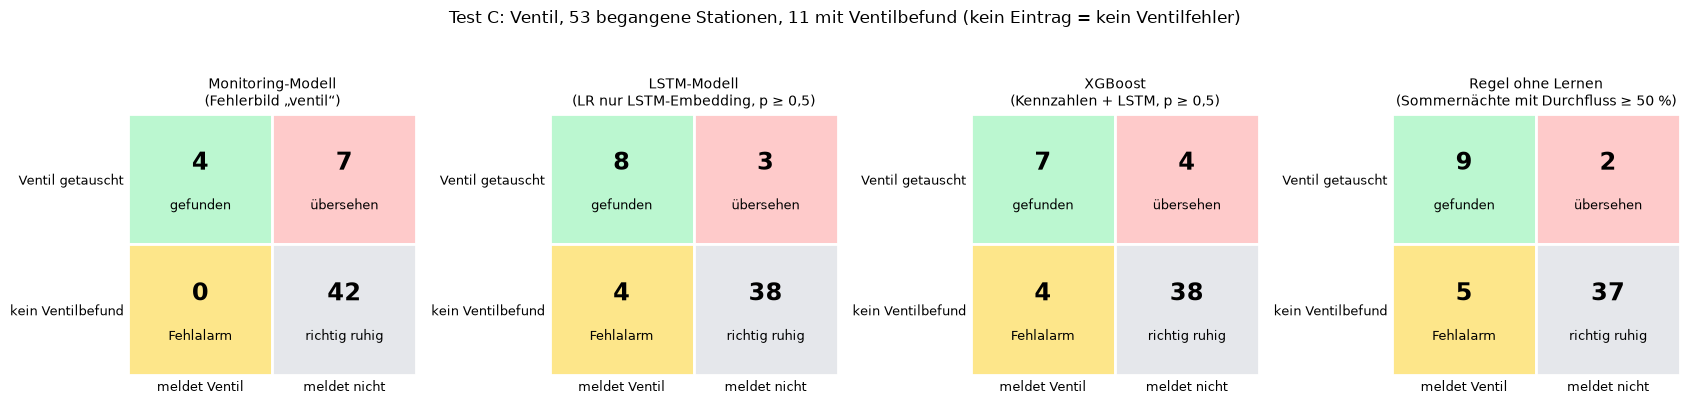

In [30]:
bv = fv.oof_breit(KL, "ventil").join(mm[["fehlerbild"]])
kandidaten_bild = [("Monitoring-Modell\n(Fehlerbild „ventil“)", bv["fehlerbild"].eq("ventil")),
                   (f"LSTM-Modell\n({fv.ENDMODELL}, p ≥ 0,5)", bv[fv.ENDMODELL] >= 0.5),
                   ("XGBoost\n(Kennzahlen + LSTM, p ≥ 0,5)", bv["XGBoost Kennzahlen + LSTM"] >= 0.5),
                   ("Regel ohne Lernen\n(Sommernächte mit Durchfluss ≥ 50 %)", bv["Regel Sommernacht-Anteil"] >= 0.5)]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, entscheidung) in zip(axes, kandidaten_bild):
    fv.zeichne_vierfeld(ax, fv.vierfeld(bv["y"], entscheidung), name, spalte_ja="meldet Ventil", spalte_nein="meldet nicht",
                        zeile_ja="Ventil getauscht", zeile_nein="kein Ventilbefund")
fig.suptitle("Test C: Ventil, 53 begangene Stationen, 11 mit Ventilbefund (kein Eintrag = kein Ventilfehler)", y=1.05)
fig.tight_layout()
fv.speichere(fig, "06_testC_ventil")
plt.show()

Beim Ventil sind alle Kandidaten deutlich besser als Raten. Das Modell, das später ins Dashboard kommt, die Regression nur auf den 16 LSTM-Zahlen (`fv.ENDMODELL`), erreicht eine AUC von 0,83 [0,64; 0,98]. Die Sommernacht-Regel kommt auf 0,85 [0,68; 0,98], der Unterschied ist nicht gesichert. An der festen Grenze findet das LSTM-Modell 8 von 11 Ventilen bei 4 Fehlalarmen, die Regel 9 bei 5. Das Fehlerbild „ventil“ des Monitoring-Modells ist genau, aber streng: 4 von 4 richtig, gefunden aber nur 4 von 11. Es taugt deshalb gut als Bestätigung.

### 8.2 Dämmung

In [31]:
tab_daemmung = fv.bewertung_tabelle(KL, mm, e["gruppen"], "daemmung")
tab_daemmung.round(3)

,Kandidat,Stationen,Befunde,AUC,AUC unten,AUC oben,Differenz zu LR Kennzahlen,Diff. unten,Diff. oben,gefunden,übersehen,Fehlalarm,richtig ruhig,Precision,Recall,F1
0,LR Kennzahlen,53,22,0.735,0.589,0.864,NaN,NaN,NaN,14.0,8.0,7.0,24.0,0.667,0.636,0.651
1,LR Kennzahlen + LSTM,53,22,0.802,0.664,0.919,0.067,-0.045,0.183,14.0,8.0,5.0,26.0,0.737,0.636,0.683
2,LR nur LSTM-Embedding,53,22,0.789,0.648,0.905,0.054,-0.062,0.179,15.0,7.0,7.0,24.0,0.682,0.682,0.682
3,XGBoost Kennzahlen,53,22,0.686,0.524,0.834,-0.048,-0.180,0.073,14.0,8.0,10.0,21.0,0.583,0.636,0.609
4,XGBoost Kennzahlen + LSTM,53,22,0.865,0.744,0.956,0.130,0.006,0.264,15.0,7.0,4.0,27.0,0.789,0.682,0.732
5,Monitoring-Modell (Netz-Score / Fehlerbild),53,22,0.380,0.214,0.552,-0.355,-0.587,-0.108,NaN,NaN,NaN,NaN,NaN,NaN,NaN


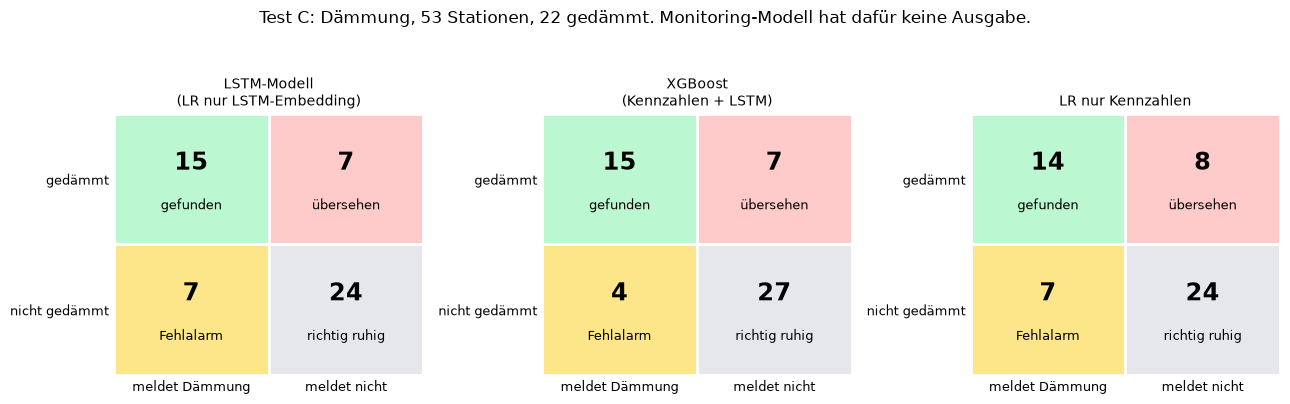

In [32]:
bd = fv.oof_breit(KL, "daemmung")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, spalte) in zip(axes, [(f"LSTM-Modell\n({fv.ENDMODELL})", fv.ENDMODELL),
                                     ("XGBoost\n(Kennzahlen + LSTM)", "XGBoost Kennzahlen + LSTM"),
                                     ("LR nur Kennzahlen", "LR Kennzahlen")]):
    fv.zeichne_vierfeld(ax, fv.vierfeld(bd["y"], bd[spalte] >= 0.5), name, spalte_ja="meldet Dämmung",
                        spalte_nein="meldet nicht", zeile_ja="gedämmt", zeile_nein="nicht gedämmt")
fig.suptitle("Test C: Dämmung, 53 Stationen, 22 gedämmt. Monitoring-Modell hat dafür keine Ausgabe.", y=1.05)
fig.tight_layout()
fv.speichere(fig, "07_testC_daemmung")
plt.show()

Bei der Dämmung kommt das Dashboard-Modell auf 0,79 [0,65; 0,90], die Kennzahlen allein auf 0,73. Der Vorsprung ist nicht gesichert. Gegen die beste an den Befunden angepasste Regel (0,61) liegt das Modell deutlich vorn, aber auch das knapp nicht gesichert (Abschnitt 14). Der Netz-Score des Monitoring-Modells zeigt sogar in die umgekehrte Richtung (0,38). Eine physikalische Erklärung für das Muster fehlt.

### 8.3 Überdimensionierung (Kapazitätsanpassung) und übrige Maßnahmen

In [33]:
tab_ueber = fv.bewertung_tabelle(KL, mm, e["gruppen"], "ueberdimensioniert")
tab_ueber.round(3)

,Kandidat,Stationen,Befunde,AUC,AUC unten,AUC oben,Differenz zu LR Kennzahlen,Diff. unten,Diff. oben,gefunden,übersehen,Fehlalarm,richtig ruhig,Precision,Recall,F1
0,LR Kennzahlen,35,9,0.393,0.184,0.629,NaN,NaN,NaN,2.0,7.0,10.0,16.0,0.167,0.222,0.190
1,LR Kennzahlen + LSTM,35,9,0.325,0.121,0.546,-0.068,-0.260,0.107,2.0,7.0,11.0,15.0,0.154,0.222,0.182
2,LR nur LSTM-Embedding,35,9,0.491,0.264,0.724,0.098,-0.123,0.343,2.0,7.0,9.0,17.0,0.182,0.222,0.200
3,Regel Auslastung zum Vertrag,35,9,0.759,0.583,0.925,0.365,0.042,0.650,5.0,4.0,1.0,25.0,0.833,0.556,0.667
4,XGBoost Kennzahlen,35,9,0.530,0.328,0.727,0.137,-0.115,0.384,1.0,8.0,7.0,19.0,0.125,0.111,0.118
5,XGBoost Kennzahlen + LSTM,35,9,0.462,0.273,0.652,0.068,-0.200,0.308,0.0,9.0,7.0,19.0,0.000,0.000,0.000
6,Monitoring-Modell (Netz-Score / Fehlerbild),35,9,0.598,0.352,0.837,0.205,-0.107,0.500,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
rest = []
for ziel in ["durchfluss", "temperatur", "filter"]:
    t = fv.bewertung_tabelle(KL, mm, e["gruppen"], ziel)
    for _, z in t.iterrows():
        rest.append({"Maßnahme": fv.ZIEL_TEXT[ziel], "Kandidat": z["Kandidat"], "Befunde": z["Befunde"],
                     "AUC": z["AUC"], "AUC unten": z["AUC unten"], "AUC oben": z["AUC oben"]})
rest = pd.DataFrame(rest)
rest.pivot_table(index="Kandidat", columns="Maßnahme", values="AUC").round(2)

Maßnahme,Durchfluss neu eingestellt,Filter gereinigt,Rücklauf-Sollwert gesenkt
Kandidat,,,
LR Kennzahlen,0.32,0.43,0.38
LR Kennzahlen + LSTM,0.29,0.30,0.33
LR nur LSTM-Embedding,0.36,0.31,0.30
Monitoring-Modell (Netz-Score / Fehlerbild),0.53,0.57,0.51
XGBoost Kennzahlen,0.37,0.48,0.38
XGBoost Kennzahlen + LSTM,0.42,0.46,0.26


Bei der Überdimensionierung trägt nur die Regel „Spitzenlast zum alten Vertrag“ (0,76 [0,58; 0,93], 5 von 9 bei 1 Fehlalarm), gelernte Modelle kommen höchstens auf 0,53. Durchfluss, Sollwert und Filter erkennt keiner (AUC 0,26 bis 0,57), das Dashboard zeigt sie deshalb nicht als Fehlerart. Werte deutlich unter 0,5 sind dabei kein umgekehrtes Signal, denn bei kleinen Stichproben landen Modelle ohne Zusammenhang oft darunter.

### 8.4 Stabilität bei anderen Startgewichten

Der Fingerabdruck hängt von den zufälligen Startgewichten des Netzes ab. Deshalb laufen dieselben Durchgänge mit zwei weiteren Seeds.

In [35]:
stab = fv.stabilitaet(e, seeds=(1, 2), log=lambda *a: None)
haupt = []
for ziel in ("ventil", "daemmung"):
    b = fv.oof_breit(KL, ziel)
    for c in ("LR Kennzahlen + LSTM", "LR nur LSTM-Embedding", "XGBoost Kennzahlen + LSTM"):
        from sklearn.metrics import roc_auc_score
        vf = fv.vierfeld(b["y"], b[c] >= 0.5)
        haupt.append({"Seed": 0, "Ziel": ziel, "Kandidat": c, "AUC": roc_auc_score(b["y"], b[c]),
                      "gefunden": vf["gefunden"], "Fehlalarm": vf["Fehlalarm"]})
stab = pd.concat([pd.DataFrame(haupt), stab], ignore_index=True)
stab.pivot_table(index=["Ziel", "Kandidat"], columns="Seed", values="AUC").round(3)

Seed                                    0      1      2
Ziel     Kandidat                                      
daemmung LR Kennzahlen + LSTM       0.802  0.796  0.836
         LR nur LSTM-Embedding      0.789  0.789  0.768
         XGBoost Kennzahlen + LSTM  0.865  0.765  0.743
ventil   LR Kennzahlen + LSTM       0.883  0.890  0.885
         LR nur LSTM-Embedding      0.833  0.840  0.903
         XGBoost Kennzahlen + LSTM  0.877  0.842  0.877

Mit anderen Startwerten kommt das Dashboard-Modell beim Ventil auf 0,84 und 0,90, bei der Dämmung auf 0,79 und 0,77. Beim Ventil schwankt es damit stärker als die Variante mit Kennzahlen (0,88 bis 0,89).

### 8.5 Gegenprobe: Encoder auf allen Stationen statt nur auf begangenen

In [36]:
from sklearn.metrics import roc_auc_score
namen = ("LR Kennzahlen + LSTM", "LR nur LSTM-Embedding", "XGBoost Kennzahlen + LSTM")
KL_alle = fv.klassifikation(e, log=lambda *a: None, ziele=("ventil", "daemmung"), kandidaten=namen, nur_begangene=False)
zeilen = []
for fassung, kl in (("nur begangene (Hauptlauf)", KL), ("alle Stationen (Gegenprobe)", KL_alle)):
    for ziel in ("ventil", "daemmung"):
        b = fv.oof_breit(kl, ziel)
        for c in namen:
            vf = fv.vierfeld(b["y"], b[c] >= 0.5)
            zeilen.append({"Encoder gelernt auf": fassung, "Ziel": ziel, "Kandidat": c, "AUC": roc_auc_score(b["y"], b[c]),
                           "gefunden": vf["gefunden"], "Fehlalarm": vf["Fehlalarm"]})
vergleich_beg = pd.DataFrame(zeilen)
vergleich_beg.pivot_table(index=["Ziel", "Kandidat"], columns="Encoder gelernt auf", values=["AUC", "Fehlalarm"]).round(3)

AUC                                             Fehlalarm                          
Encoder gelernt auf                alle Stationen (Gegenprobe) nur begangene (Hauptlauf) alle Stationen (Gegenprobe) nur begangene (Hauptlauf)
Ziel     Kandidat                                                                                                                             
daemmung LR Kennzahlen + LSTM                            0.782                     0.802                         7.0                       5.0
         LR nur LSTM-Embedding                           0.812                     0.789                         7.0                       7.0
         XGBoost Kennzahlen + LSTM                       0.716                     0.865                         6.0                       4.0
ventil   LR Kennzahlen + LSTM                            0.881                     0.883                         5.0                       3.0
         LR nur LSTM-Embedding                           0.866                     0.833                         6.0                       4.0
         XGBoost Kennzahlen + LSTM                       0.805                     0.877                         3.0                       4.0

Lernt der Fingerabdruck auf allen Stationen statt nur auf begangenen, liegt das Dashboard-Modell beim Ventil etwas höher (0,87 statt 0,83), hat aber mehr Fehlalarme (6 statt 4). Es bleibt deshalb bei der Vorgabe, nur auf begangenen Stationen zu lernen.

### 8.6 XGBoost erklärt: welche Merkmale den Ventilverdacht tragen

XGBoost zerlegt jede Entscheidung in Beiträge je Merkmal (TreeSHAP), positive Beiträge heben den Verdacht. Ausgangswert plus alle Beiträge ergibt den Logit, daraus folgt p = 1 / (1 + e^(−Logit)).

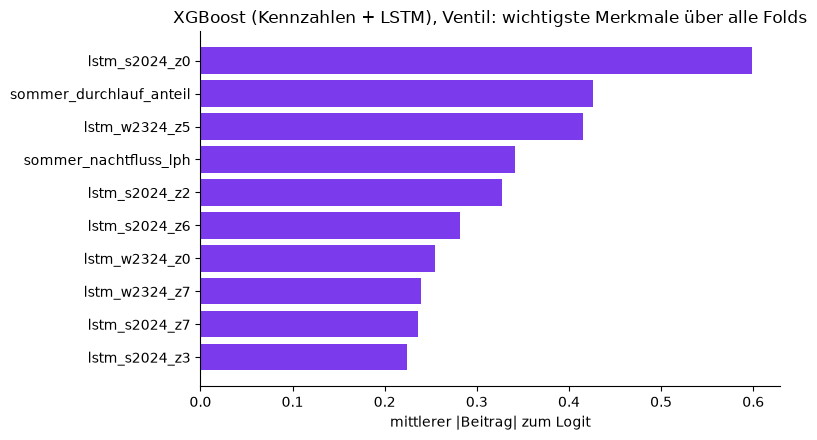

Die 5 wichtigsten Merkmale je Fold:
  Fold 0: lstm_s2024_z0, lstm_w2324_z4, lstm_w2324_z2, lstm_w2324_z7, lstm_w2324_z5
  Fold 1: lstm_s2024_z2, lstm_w2324_z7, sommer_durchlauf_anteil, streubreite_betriebspunkte, lstm_s2024_z6
  Fold 2: sommer_nachtfluss_lph, lstm_s2024_z6, lstm_w2324_z5, lstm_s2024_z0, lstm_w2324_z2
  Fold 3: sommer_durchlauf_anteil, lstm_s2024_z7, lstm_s2024_z3, lstm_w2324_z0, lstm_s2024_z2
  Fold 4: lstm_w2324_z5, lstm_w2324_z0, lstm_s2024_z0, lstm_s2024_z5, lstm_s2024_z4


In [37]:
beitr = KL["beitraege"].drop(columns=["fold"])
wichtig = beitr.drop(columns="basis").abs().mean().sort_values(ascending=False)
je_fold = KL["beitraege"].groupby("fold").apply(lambda g: g.drop(columns=["fold", "basis"], errors="ignore").abs().mean().nlargest(5).index.tolist())
fig, ax = plt.subplots(figsize=(8, 4.5))
top = wichtig.head(10)[::-1]
ax.barh(top.index, top.values, color=fv.FARBE_XGB)
ax.set_xlabel("mittlerer |Beitrag| zum Logit")
ax.set_title("XGBoost (Kennzahlen + LSTM), Ventil: wichtigste Merkmale über alle Folds")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fv.speichere(fig, "08_xgboost_beitraege")
plt.show()
print("Die 5 wichtigsten Merkmale je Fold:")
for k, liste in je_fold.items():
    print(f"  Fold {k}: {', '.join(liste)}")

In [38]:
fall = 68956351 if 68956351 in beitr.index else beitr.index[0]
b = beitr.loc[fall]
logit = b.sum()
zerlegung = b.drop("basis").sort_values(key=np.abs, ascending=False).head(6)
print(f"Station {fall}: Ausgangswert {b['basis']:+.2f}")
for name, wert in zerlegung.items():
    print(f"   {name:32s} {wert:+.2f}")
print(f"   übrige Merkmale                  {b.drop(['basis', *zerlegung.index]).sum():+.2f}")
print(f"Summe (Logit) {logit:+.2f}  ->  p(Ventil) = {1 / (1 + np.exp(-logit)):.2f}")
print("Kennzahlen dieser Station:", KL["kz"].loc[fall, ["sommer_durchlauf_anteil", "sommer_nachtfluss_lph", "winter_spreizung_last_k"]].round(2).to_dict())

Station 68956351: Ausgangswert +0.58
   sommer_nachtfluss_lph            +0.85
   lstm_s2024_z6                    -0.73
   lstm_w2324_z2                    +0.60
   lstm_s2024_z0                    -0.56
   lstm_w2324_z5                    +0.54
   winter_nacht_tag_fluss           -0.41
   übrige Merkmale                  +0.57
Summe (Logit) +1.43  ->  p(Ventil) = 0.81
Kennzahlen dieser Station: {'sommer_durchlauf_anteil': 1.0, 'sommer_nachtfluss_lph': 518.0, 'winter_spreizung_last_k': 5.91}


XGBoost ist nicht verlässlich. Beim Ventil kommt es im Test auf 0,88, in der Validierung aber hinter die Regression (0,81 gegen 0,84, Abschnitt 15.2). Bei der Dämmung erreicht es 0,87, mit anderen Startwerten aber nur 0,77 und 0,74. Die wichtigsten Merkmale wechseln je Durchgang, stabil sind nur der Nachtdurchfluss und der Sommernacht-Anteil. XGBoost kommt deshalb nicht ins Dashboard.

### 8.7 Die drei Klassen

Beim Befund gibt es die Reparatur (Ventil getauscht), die Regelungsoptimierung (Durchfluss eingestellt oder Sollwert gesenkt) und keine dieser Maßnahmen. Das LSTM-Modell nimmt p(Ventil) ≥ 0,5 und sonst K-Means, das Monitoring-Modell das Fehlerbild „ventil“, sonst ein anderes Fehlerbild und sonst keins.

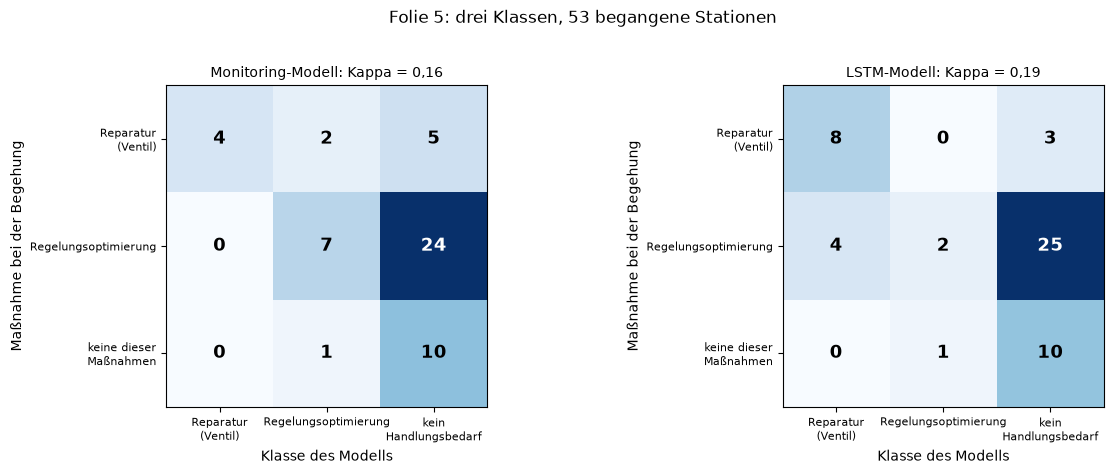

In [39]:
f5_befund = fv.folie5_befund(e["labels"].loc[KL["basis"].index])
p_v = fv.oof_breit(KL, "ventil")[fv.ENDMODELL]
f5_lstm = fv.folie5_lstm(p_v, KL["kmeans_klasse"].reindex(p_v.index))
f5_mm = fv.folie5_monitoring(mm["fehlerbild"].reindex(p_v.index).fillna(""))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, (name, vorhersage) in zip(axes, [("Monitoring-Modell", f5_mm), ("LSTM-Modell", f5_lstm)]):
    m = pd.crosstab(f5_befund, vorhersage).reindex(index=fv.F5_KLASSEN, columns=fv.F5_KLASSEN, fill_value=0)
    m.index = ["Reparatur (Ventil)", "Regelungsoptimierung", "keine dieser Maßnahmen"]
    k = fv.kappa(f5_befund, vorhersage)
    fv.zeichne_matrix(ax, m, f"{name}: Kappa = {k:.2f}".replace(".", ","), "Klasse des Modells", "Maßnahme bei der Begehung")
fig.suptitle("Folie 5: drei Klassen, 53 begangene Stationen", y=1.02)
fig.tight_layout()
fv.speichere(fig, "09_folie5_matrizen")
plt.show()

Die Reparatur trifft das Monitoring-Modell 4 von 11 Mal, das LSTM-Modell 8 von 11 Mal. Die Regelungsoptimierung trifft keins, 24 bzw. 25 von 31 Fällen landen bei „kein Handlungsbedarf“ (Kappa 0,16 und 0,19). Regelungsoptimierung empfiehlt das Dashboard deshalb nicht.

### 8.8 Gegenprobe mit späteren Daten: sinkt der Ventilverdacht nach dem Tausch?

Beide Modelle laufen unverändert auf Winter 24/25 und, soweit vorhanden, Sommer 2025, also nach den Begehungen. Wo das Ventil getauscht wurde, sollte der Verdacht sinken. Das ist eine Prüfung an bekannten Stationen in späterer Zeit, ohne neu zu lernen.

In [40]:
teile = fv.fehlerklassen_teile(KL)
gp = fv.gegenprobe_nach_reparatur(teile, e, KL, netz)
from scipy import stats
zeilen = []
for gruppe, g in gp.groupby("gruppe"):
    g2 = g.dropna(subset=["p_ventil_vor", "p_ventil_nach"])
    p = stats.wilcoxon(g2["p_ventil_vor"], g2["p_ventil_nach"]).pvalue if len(g2) >= 6 else np.nan
    zeilen.append({"Gruppe": gruppe, "Stationen": len(g2), "p(Ventil) vorher, Median": g2["p_ventil_vor"].median(),
                   "p(Ventil) nachher, Median": g2["p_ventil_nach"].median(), "p (Wilcoxon)": p,
                   "Monitoring „ventil“ vorher": int(g["fehlerbild_vor"].eq("ventil").sum()),
                   "Monitoring „ventil“ nachher": int(g["fehlerbild_nach"].eq("ventil").sum())})
pd.DataFrame(zeilen).round(3)

,Gruppe,Stationen,"p(Ventil) vorher, Median","p(Ventil) nachher, Median",p (Wilcoxon),Monitoring „ventil“ vorher,Monitoring „ventil“ nachher
0,Ventil getauscht,11,0.707,0.254,0.042,4,1
1,"begangen, kein Ventil",43,0.265,0.075,0.000,0,1
2,nie begangen,37,0.301,0.231,0.066,4,4


Wo das Ventil getauscht wurde, sinkt der Score im Median von 0,71 auf 0,25 (p = 0,04), und das Fehlerbild „ventil“ des Monitoring-Modells geht von 4 auf 1 zurück. Der Score sinkt aber auch an begangenen Stationen ohne Ventiltausch (0,27 auf 0,08, p < 0,001), an nie begangenen kaum (0,30 auf 0,23, p = 0,07). Er reagiert also auf jede Veränderung nach einer Begehung, während die Variante mit Kennzahlen dort ruhig blieb (0,11 auf 0,08). Das Fehlerbild reagiert dagegen gezielt auf die Reparatur.

## 9 Test D: Dauerhaft schlecht, Effizienz und Potenzial

Zuerst wird die Übereinstimmung geprüft, das Potenzial des Monitoring-Modells im Winter 23/24 gegen die K-Means-Gruppe (Optimum oder schlechter) aus dem LSTM-Strang. Die Wirkung misst die Abkühlung bei 5 °C (kWh je m³) im Winter 24/25 minus 23/24 für begangene gegen nicht begangene Stationen, mehr Abkühlung heißt effizienter. Beim Potenzial geht es darum, ob es vor der Begehung anzeigt, wo sie am meisten brachte.

In [41]:
wp = fv.wirkung_und_potenzial(w, netz, KL, termine)
pot_hoch = wp["potenzial"].isin(["mittel", "hoch"])
km_schlecht = wp["kmeans"].eq("schlechter")
print("Kappa Potenzial (mittel/hoch) gegen K-Means „schlechter“:", round(fv.kappa(pot_hoch[wp["kmeans"].notna()], km_schlecht[wp["kmeans"].notna()]), 2))
print(pd.crosstab(wp["potenzial"].replace("", "ohne"), wp["kmeans"].fillna("ohne"), margins=True))

Kappa Potenzial (mittel/hoch) gegen K-Means „schlechter“: 0.39
kmeans     Optimum  schlechter  All
potenzial                          
gering          37           0   37
hoch             7          13   20
mittel          18           4   22
All             62          17   79


Abkühlung bei 5 °C, Winter 24/25 minus 23/24: begangen +0.26 kWh/m³ (n = 41), nicht begangen -0.56 (n = 38); Unterschied +0.82, p = 0.371
Begangene: Potenzial vorher gegen Verbesserung, Spearman rho = 0.16, p = 0.304
Begangene, Verbesserung nach K-Means-Gruppe (Median): {'Optimum': -0.29, 'schlechter': 1.6} | n: {'Optimum': 34, 'schlechter': 7}


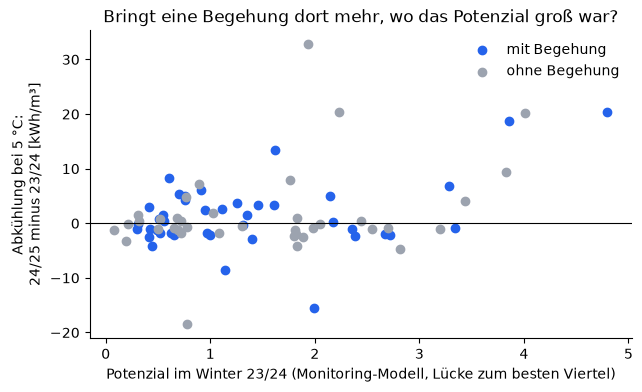

In [42]:
beg = wp[wp["begangen"]]
nicht = wp[~wp["begangen"]]
did = beg["delta_kwh_m3"].median() - nicht["delta_kwh_m3"].median()
p_mw = stats.mannwhitneyu(beg["delta_kwh_m3"], nicht["delta_kwh_m3"], alternative="greater").pvalue
rho, p_rho = stats.spearmanr(beg["potenzial_score"], beg["delta_kwh_m3"], nan_policy="omit")
print(f"Abkühlung bei 5 °C, Winter 24/25 minus 23/24: begangen {beg['delta_kwh_m3'].median():+.2f} kWh/m³ (n = {len(beg)}), "
      f"nicht begangen {nicht['delta_kwh_m3'].median():+.2f} (n = {len(nicht)}); Unterschied {did:+.2f}, p = {p_mw:.3f}")
print(f"Begangene: Potenzial vorher gegen Verbesserung, Spearman rho = {rho:.2f}, p = {p_rho:.3f}")
km = beg.dropna(subset=["kmeans"])
print("Begangene, Verbesserung nach K-Means-Gruppe (Median):", km.groupby("kmeans")["delta_kwh_m3"].median().round(2).to_dict(),
      "| n:", km["kmeans"].value_counts().to_dict())
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(beg["potenzial_score"], beg["delta_kwh_m3"], color=fv.FARBE_MONITORING, label="mit Begehung")
ax.scatter(nicht["potenzial_score"], nicht["delta_kwh_m3"], color="#9CA3AF", label="ohne Begehung")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Potenzial im Winter 23/24 (Monitoring-Modell, Lücke zum besten Viertel)")
ax.set_ylabel("Abkühlung bei 5 °C:\n24/25 minus 23/24 [kWh/m³]")
ax.set_title("Bringt eine Begehung dort mehr, wo das Potenzial groß war?")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fv.speichere(fig, "10_potenzial_wirkung")
plt.show()

Potenzial und K-Means passen mittelmäßig zusammen (Kappa 0,39). Alle 17 Stationen „schlechter“ haben mittleres oder hohes Potenzial, das Monitoring-Modell sieht aber 25 weitere. Dauerhaft schlechten Betrieb sieht nur der Netzvergleich, wie Fall 1 zeigt, der mit drei Jahren offenem Ventil vor der Reparatur auf Rang 1 stand.

Begangene Stationen kühlen im Winter 24/25 um 0,26 kWh/m³ besser, nicht begangene um 0,56 schlechter. Der Unterschied von 0,82 kWh/m³ ist nicht gesichert (p = 0,37). Das Potenzial sagt kaum vorher, wo eine Begehung am meisten bringt (rho = 0,16, p = 0,30). K-Means „schlechter“ verbessert sich stärker (+1,6 gegen −0,3 kWh/m³), aber nur bei 7 Stationen. Im Dashboard beschreiben Netzeffizienz, Rang und Potenzial deshalb nur die Lage im Netz, ohne Prognose der Einsparung und ohne Euro- oder Prozentwerte.

## 10 Test E: Reihenfolge der Empfehlungen

Wenn das Team nur 10 Stationen begehen kann, wie viele davon hatten einen Ventilbefund? Die 53 begangenen Stationen werden dafür sortiert nach der Priorität des Monitoring-Modells (dann Netz-Score), nach p(Ventil) des LSTM-Modells, nach XGBoost und nach der Sommernacht-Regel. Zufall ergäbe etwa 2 (10 × 11/53).

In [43]:
rang = fv.oof_breit(KL, "ventil").join(mm[["prioritaet", "netz_score"]])
stufe = rang["prioritaet"].map({"hoch": 2, "mittel": 1, "niedrig": 0}).fillna(-1)
listen = {"Monitoring-Modell (Priorität, dann Netz-Score)": stufe * 100 + rang["netz_score"].fillna(-99),
          "LSTM-Modell (p Ventil)": rang[fv.ENDMODELL],
          "XGBoost (p Ventil)": rang["XGBoost Kennzahlen + LSTM"],
          "Regel Sommernacht-Anteil": rang["Regel Sommernacht-Anteil"]}
zeilen = []
for name, s in listen.items():
    top = s.sort_values(ascending=False).index[:10]
    zeilen.append({"Reihenfolge nach": name, "Ventilbefunde unter den ersten 10": int(rang.loc[top, "y"].sum())})
print("Priorität des Monitoring-Modells unter den 53:", rang["prioritaet"].value_counts().to_dict())
print("davon mit Ventilbefund:", rang.groupby("prioritaet")["y"].sum().to_dict())
pd.DataFrame(zeilen)

Priorität des Monitoring-Modells unter den 53: {'niedrig': 31, 'mittel': 21, 'hoch': 1}
davon mit Ventilbefund: {'hoch': 1, 'mittel': 6, 'niedrig': 4}


,Reihenfolge nach,Ventilbefunde unter den ersten 10
0,"Monitoring-Modell (Priorität, dann Netz-Score)",5
1,LSTM-Modell (p Ventil),7
2,XGBoost (p Ventil),7
3,Regel Sommernacht-Anteil,7


Unter den ersten 10 finden LSTM-Modell, XGBoost und Sommernacht-Regel je 7 Ventilbefunde, die Priorität des Monitoring-Modells 5, Zufall etwa 2. Die Stufe „hoch“ des Monitoring-Modells hatte vor den Begehungen nur 1 der 53 Stationen (mit Ventilbefund), „mittel“ 21 (davon 6 mit Ventil), für eine Reihenfolge zu grob. Daraus folgt, umgesetzt in `dashboard_daten.empfehlungen`, eine Reparaturliste nach dem Ventil-Score des LSTM-Modells, wobei das Fehlerbild „ventil“ des Monitoring-Modells auf „hoch“ hebt. Die Stufen sind gesetzt, nicht gelernt. Ein echter Test wäre prospektiv, bei dem Stationen der Stufe „hoch“ und gleich viele zufällige blind begangen werden.

## 11 Neue Stationen, spätere Zeit, Jahreszeiten

Im Betrieb soll ein Modell auch in späterer Zeit, an neuen Stationen und in jeder Jahreszeit funktionieren. Spätere Zeit ist mit Test A und B ab Juni 2024 und der Gegenprobe im Winter 24/25 (8.8) schon geprüft, neue Stationen bei der Fehlerart mit Test C, weil die Teststationen nie im Lernen waren. Offen sind neue Stationen beim Wächter und die Jahreszeiten. Dafür lernt das LSTM hier einmal ohne ein Fünftel der Stationen, und der Vorhersagefehler wird je Monat verglichen.

In [44]:
neu = fv.lstm_neue_stationen(e, w, log=lambda *a: None)
t = neu["tage"]
print(len(neu["neu"]), "Stationen nie gesehen, gleiche Testtage für alle drei")
mae = t.groupby(["modell", "zaehler"])[["mae_rl", "mae_fluss"]].mean().groupby("modell").agg(["mean", "count"])
mae.round(2)

17 Stationen nie gesehen, gleiche Testtage für alle drei


mae_rl       mae_fluss      
                                  mean count      mean count
modell                                                      
Wochenmittel (ohne Lernen)        4.35    15     54.80    15
bekannt (Station war im Lernen)   3.49    15     46.33    15
neu (Station nie gesehen)         4.02    15     49.00    15

In [45]:
breit = t.groupby(["zaehler", "modell"])["mae_rl"].mean().unstack()
diff = (breit["neu (Station nie gesehen)"] - breit["bekannt (Station war im Lernen)"]).to_numpy()
rng = np.random.default_rng(0)
boot = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(2000)]
print(f"Rücklauf-Fehler neue minus bekannte Station: {diff.mean():+.2f} K, 95 % [{np.quantile(boot, .025):+.2f}; {np.quantile(boot, .975):+.2f}]")
diff_wm = (breit["neu (Station nie gesehen)"] - breit["Wochenmittel (ohne Lernen)"]).to_numpy()
boot = [diff_wm[rng.integers(0, len(diff_wm), len(diff_wm))].mean() for _ in range(2000)]
print(f"Rücklauf-Fehler neue Station minus Wochenmittel: {diff_wm.mean():+.2f} K, 95 % [{np.quantile(boot, .025):+.2f}; {np.quantile(boot, .975):+.2f}]")

Rücklauf-Fehler neue minus bekannte Station: +0.54 K, 95 % [+0.20; +1.07]
Rücklauf-Fehler neue Station minus Wochenmittel: -0.32 K, 95 % [-1.00; +0.40]


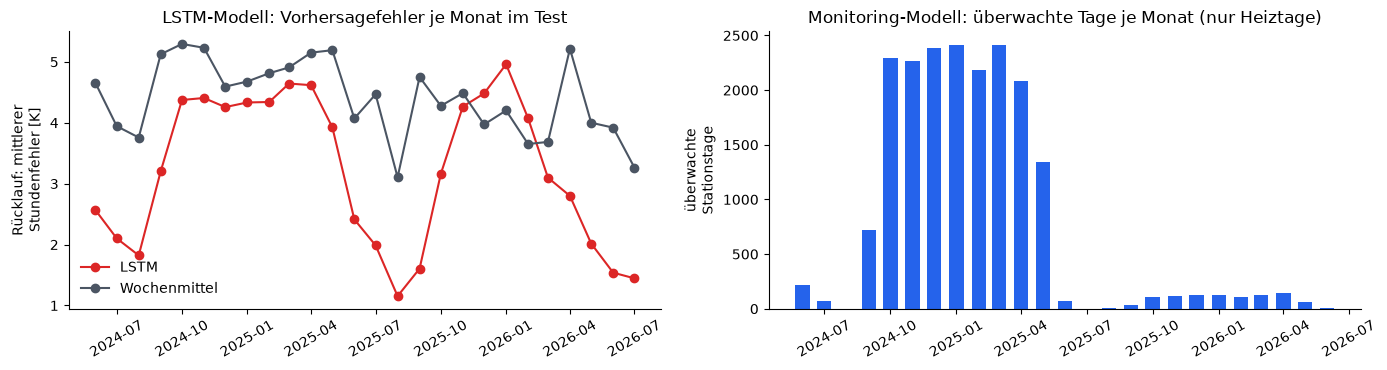

In [46]:
monat = w["abw"][w["abw"]["tag"] >= fv.TEST_START].assign(monat=lambda d: d["tag"].dt.to_period("M"))
monat_wm = w["abw_wm"][w["abw_wm"]["tag"] >= fv.TEST_START].assign(monat=lambda d: d["tag"].dt.to_period("M"))
v = w["verlauf"][(w["verlauf"]["datum"] >= fv.TEST_START) & (w["verlauf"]["kanal"] == "kwh_pro_m3")]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(monat.groupby("monat")["mae_rl"].mean().to_timestamp(), "-o", color=fv.FARBE_LSTM, label="LSTM")
ax[0].plot(monat_wm.groupby("monat")["mae_rl"].mean().to_timestamp(), "-o", color="#4B5563", label="Wochenmittel")
ax[0].set_ylabel("Rücklauf: mittlerer\nStundenfehler [K]")
ax[0].set_title("LSTM-Modell: Vorhersagefehler je Monat im Test")
ax[0].legend(frameon=False)
mon = v.assign(monat=v["datum"].dt.to_period("M")).groupby("monat")
ax[1].bar(mon.size().index.to_timestamp(), mon.size().values, width=20, color=fv.FARBE_MONITORING)
ax[1].set_ylabel("überwachte\nStationstage")
ax[1].set_title("Monitoring-Modell: überwachte Tage je Monat (nur Heiztage)")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
    a.tick_params(axis="x", labelrotation=30)
fig.tight_layout()
fv.speichere(fig, "11_jahreszeiten")
plt.show()

In [47]:
bewertbar = fv.ab_wann_bewertbar(e, w)
print("Ab wann kann jedes Modell eine Station bewerten? (Tage nach dem ersten Messwert, Median über die Stationen)")
bewertbar[["Monitoring-Modell ab Tag", "LSTM-Wächter ab Tag"]].describe().loc[["count", "25%", "50%", "75%"]].round(0)

Ab wann kann jedes Modell eine Station bewerten? (Tage nach dem ersten Messwert, Median über die Stationen)


,Monitoring-Modell ab Tag,LSTM-Wächter ab Tag
count,93.0,93.0
25%,60.0,27.0
50%,60.0,29.0
75%,87.0,403.0


Beide Modelle funktionieren auf Daten nach dem Lernen. Für neue Stationen gelten bei der Fehlerart die AUC-Werte aus Test C bereits. Beim LSTM-Wächter werden 17 Stationen, die er nie gesehen hat, beim Rücklauf um 0,54 K [0,20; 1,07] schlechter vorhergesagt und sind gegen das Wochenmittel nicht gesichert besser (−0,32 K [−1,00; +0,40]). Deshalb lernt der Wächter auf allen Stationen, die er überwachen soll.

Das Monitoring-Modell braucht 60 Heiztage mit 8 K Temperaturspanne (Median 60 Tage, sonst Warten auf die nächste Heizperiode) und nutzt auch Tageswerte. Das LSTM braucht rund 4 Wochen volle Stundenwerte (Median 29 Tage), in jeder Jahreszeit. Im Sommer sagt das LSTM genauer voraus (1 bis 2,5 K) als im Winter (4 bis 5 K), das Wochenmittel liegt ganzjährig bei 4 bis 5 K. Das Monitoring-Modell überwacht nur Oktober bis April, die beiden ergänzen sich. 7 Stationen kann das Monitoring-Modell nicht einlernen, weil ihre Daten zu spät beginnen, 6 davon auch das LSTM nicht. Das Dashboard zeigt dann „noch nicht bewertbar“, nicht „kein Alarm“.

## 12 Fallbeispiele mit echten Daten

Jeder Fall hat vier Bilder: die Abkühlung gegen die Kennlinie des Monitoring-Modells, sein CUSUM-Konto mit h = 5, den Rücklauf gegen die LSTM-Erwartung und die z-Werte des LSTM. Senkrechte Linien sind Alarme, durchgezogen heißt schlechter, gepunktet besser, grün sind Begehungen. Die Fälle sind nach festen Regeln gewählt, nicht nach schönen Bildern.

{'ventil': True, 'daemmung': False, 'durchfluss': False, 'temperatur': True, 'filter': False, 'ueberdimensioniert': nan} | Begehung: ['09.09.2024']


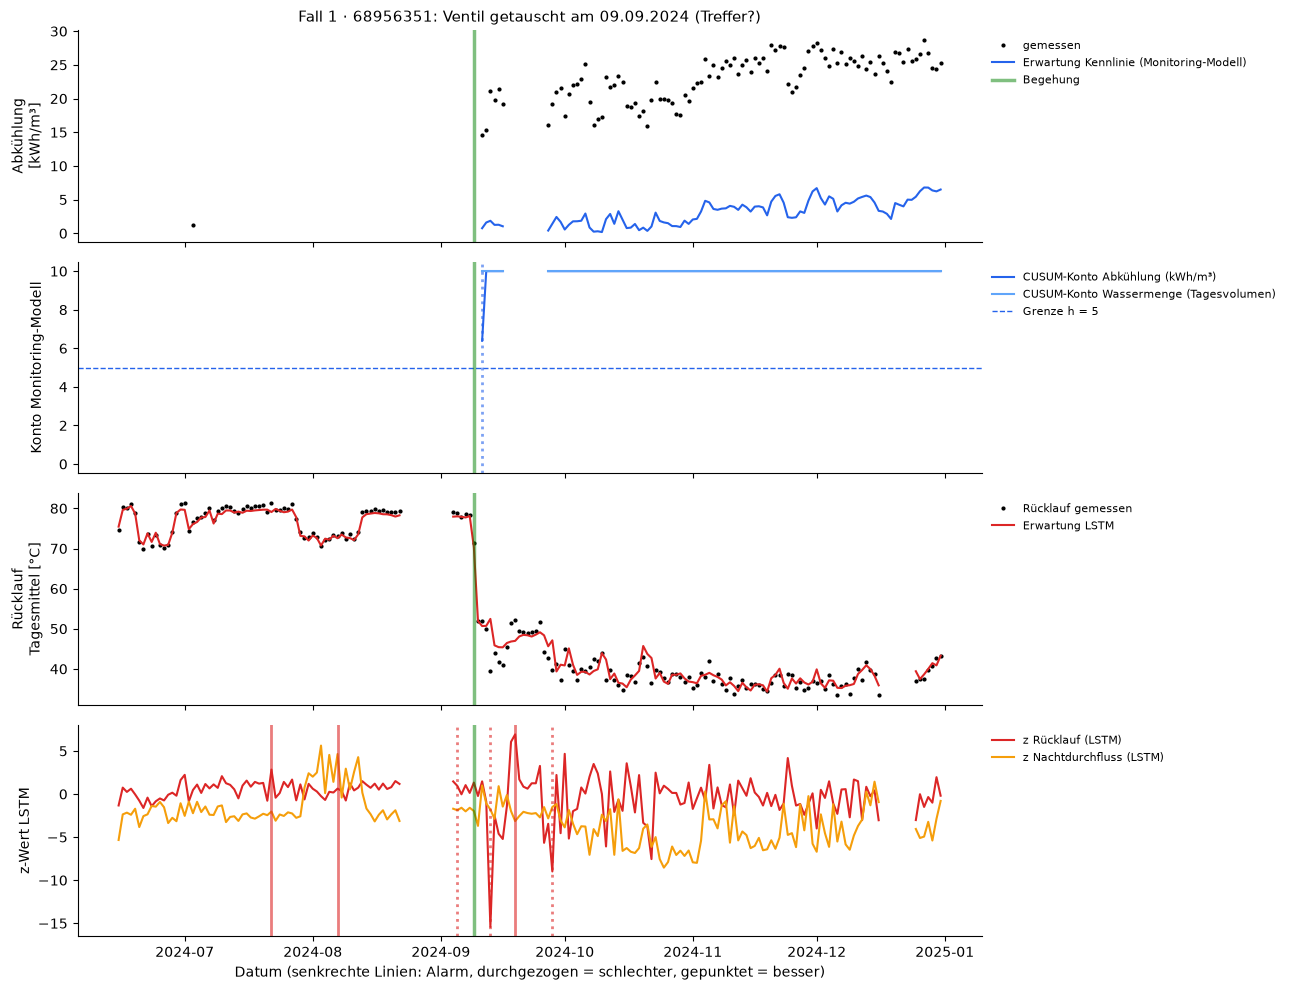

In [48]:
fall1 = 68956351
print(e["labels"].loc[fall1, fv.ZIELE].to_dict(), "| Begehung:", [f"{t:%d.%m.%Y}" for t in termine.get(fall1, [])])
fig = fv.fallbild(fall1, w, e, "2024-06-15", "2024-12-31", f"Fall 1 · {fall1}: Ventil getauscht am 09.09.2024 (Treffer?)")
fv.speichere(fig, "12_fall1")
plt.show()

Fall 2: Ventilbefund mit dem kleinsten Verdacht des LSTM-Modells (p = 0.10), Fehlerbild Monitoring-Modell: „durchfluss_je_kw“
Kennzahlen: {'sommer_durchlauf_anteil': 0.93, 'sommer_nachtfluss_lph': 46.0, 'winter_spreizung_last_k': 28.62, 'ruecklauf_lastgewichtet': 47.17}


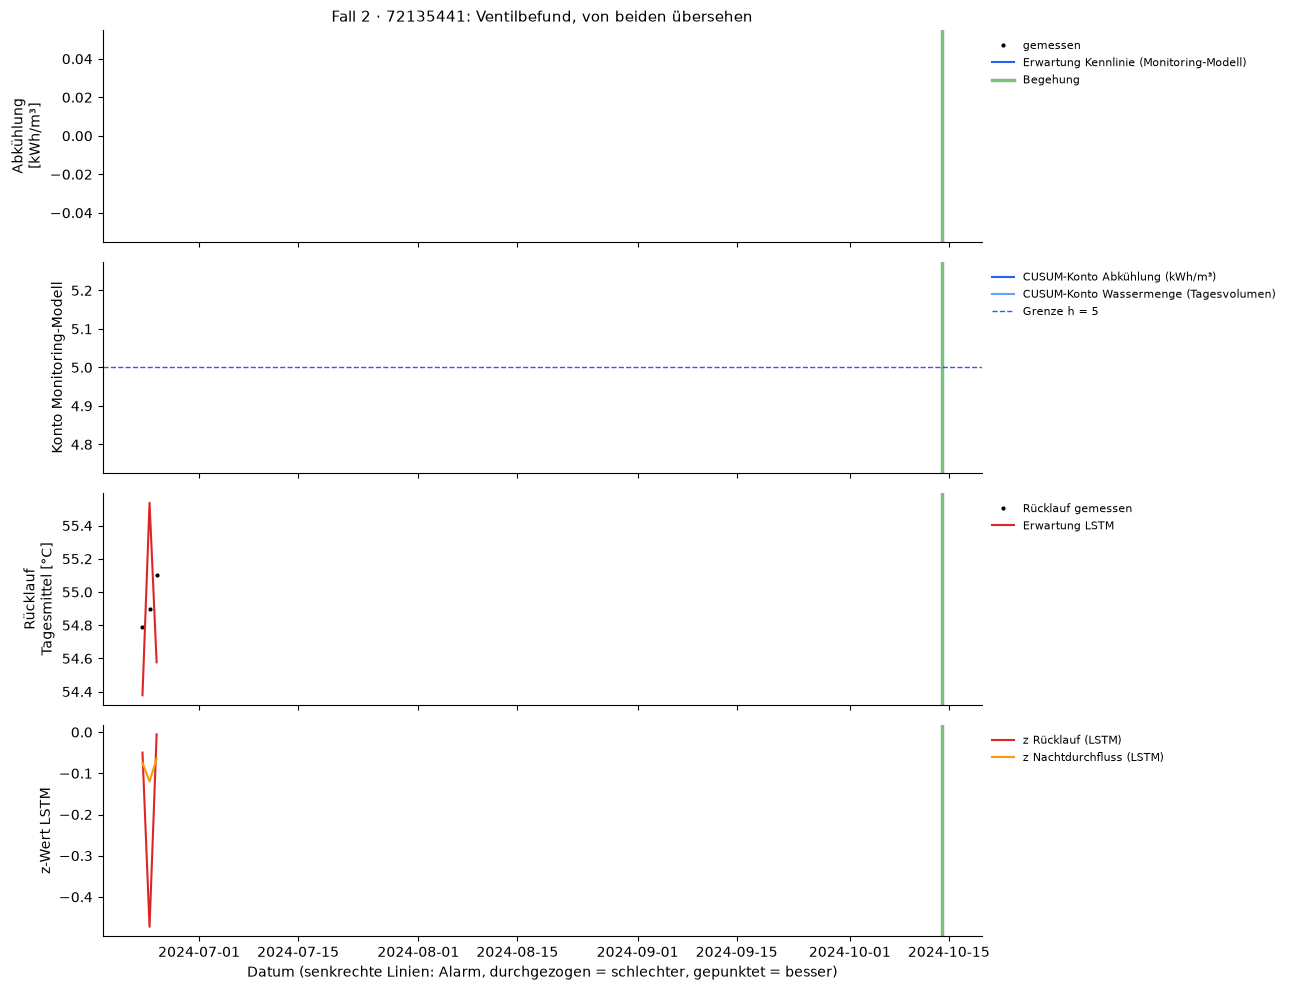

In [49]:
bv2 = fv.oof_breit(KL, "ventil").join(mm[["fehlerbild"]])
uebersehen = bv2[(bv2["y"] == 1) & ~bv2["fehlerbild"].eq("ventil")].sort_values(fv.ENDMODELL)
fall2 = int(uebersehen.index[0])
print(f"Fall 2: Ventilbefund mit dem kleinsten Verdacht des LSTM-Modells (p = {uebersehen.iloc[0][fv.ENDMODELL]:.2f}), "
      f"Fehlerbild Monitoring-Modell: „{uebersehen.iloc[0]['fehlerbild'] or 'keins'}“")
print("Kennzahlen:", KL["kz"].loc[fall2, ["sommer_durchlauf_anteil", "sommer_nachtfluss_lph", "winter_spreizung_last_k", "ruecklauf_lastgewichtet"]].round(2).to_dict())
d2 = min(termine.get(fall2, [pd.Timestamp("2024-10-01")]))
fig = fv.fallbild(fall2, w, e, d2 - pd.Timedelta(days=120), d2 + pd.Timedelta(days=90), f"Fall 2 · {fall2}: Ventilbefund, von beiden übersehen")
fv.speichere(fig, "12_fall2")
plt.show()

Fall 3: nie begangene Station mit den meisten Verschlechterungsalarmen beim Monitoring-Modell im Test: 72135453


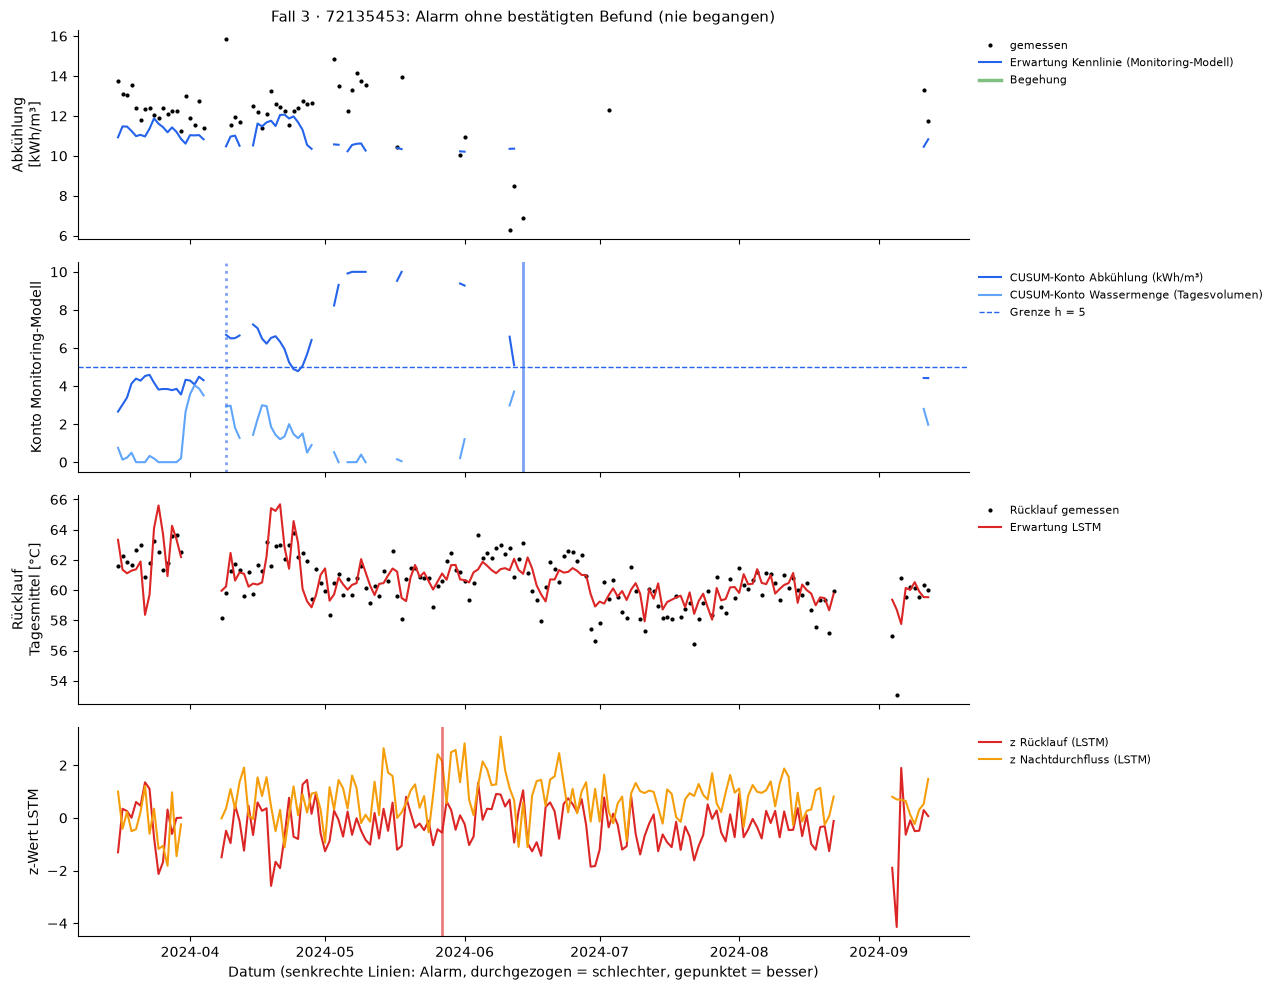

In [50]:
nie = [m for m in w["kal"].index if m not in e["labels"].index and m in set(w["ref"].index[w["ref"]["status"] == "ok"])]
al_mm_t = w["alarme"]["monitoring"]
al_mm_t = al_mm_t[(al_mm_t["datum"] >= fv.TEST_START) & al_mm_t["zaehler"].isin(nie) & (al_mm_t["bewertung"] == "schlechter")]
fall3 = int(al_mm_t["zaehler"].value_counts().index[0])
d3 = al_mm_t[al_mm_t["zaehler"] == fall3]["datum"].min()
print(f"Fall 3: nie begangene Station mit den meisten Verschlechterungsalarmen beim Monitoring-Modell im Test: {fall3}")
fig = fv.fallbild(fall3, w, e, d3 - pd.Timedelta(days=90), d3 + pd.Timedelta(days=90), f"Fall 3 · {fall3}: Alarm ohne bestätigten Befund (nie begangen)")
fv.speichere(fig, "12_fall3")
plt.show()

In [51]:
nicht_ok = w["ref"][w["ref"]["status"] != "ok"]
print("Fall 4: Stationen, die der Wächter des Monitoring-Modells mit der gemeinsamen Lernzeit nicht einlernen kann:")
display(nicht_ok[["ref_tage", "ref_spanne_k", "status"]].assign(LSTM_kalibriert=lambda d: d.index.isin(w["kal"].index)))
print("Gründe: zu wenige Heiztage vor dem Lernende, meist weil die Station erst spät Daten liefert.")

Fall 4: Stationen, die der Wächter des Monitoring-Modells mit der gemeinsamen Lernzeit nicht einlernen kann:


,ref_tage,ref_spanne_k,status,LSTM_kalibriert
meter,,,,
58177384,460,24.258333,keine Tage nach der Referenz,False
80912191,0,0.000000,zu wenige Referenztage,False
80912194,0,0.000000,zu wenige Referenztage,False
80912199,3,6.258333,zu wenige Referenztage,False
81019433,0,0.000000,zu wenige Referenztage,False
81050517,0,0.000000,zu wenige Referenztage,False
81062289,0,0.000000,zu wenige Referenztage,False


Gründe: zu wenige Heiztage vor dem Lernende, meist weil die Station erst spät Daten liefert.


Fall 1 (68956351, Ventil getauscht am 09.09.2024) ist ein Treffer für beide. Am Tag der Reparatur fällt der Rücklauf von etwa 78 auf 50 °C, und die Abkühlung steigt von etwa 1 auf über 20 kWh/m³. Das Monitoring-Modell meldet zwei Tage später „besser“, das LSTM ebenfalls im September, nachdem es im Juli und August zweimal „schlechter“ gemeldet hatte. Die Kennlinie des Monitoring-Modells stammt aus der Zeit mit offenem Ventil, danach stehen seine Konten am Deckel, und ohne neue Referenz ist der Wächter hier stumm. Das LSTM passt sich nach etwa einer Woche an. Vor der Reparatur hatten alle die Station vorn, mit Rang 1 im Netzvergleich und Fehlerbild „ventil“, einem Sommernacht-Anteil von 100 % und p(Ventil) = 0,81 bei XGBoost.

Fall 2, der Ventilbefund mit dem kleinsten Ventil-Score (p = 0,10), wird von beiden übersehen. Das Monitoring-Modell zeigt das Fehlerbild „durchfluss_je_kw“, nicht „ventil“. Die Kennzahlen sind 93 % Sommernächte mit Durchfluss, ein Nachtdurchfluss von 46 l/h und eine Spreizung bei Last von 28,6 K. Vielleicht war es ein anderer Ventilfehler oder ein anderes Ventil. Was die Daten nicht zeigen, findet kein Modell.

Fall 3 (72135453, nie begangen) ist ein Alarm ohne bestätigten Befund. Das Monitoring-Modell meldet im Juni 2024 „schlechter“. Im Übergang zum Sommer gibt es wenige Heiztage, und an ihnen fällt die Abkühlung auf 6 bis 8 kWh/m³. Das LSTM bleibt bis auf einen Tag ruhig. Das spricht eher für die Übergangszeit als für einen Defekt, und deshalb heißt ein Alarm im Dashboard „Veränderung“, nicht „Fehler“. Fall 4 sind 7 Stationen ohne Referenz, weil sie zu spät Daten liefern. Ehrlich ist hier „noch nicht bewertbar“.

## 13 Modelle speichern

Gespeichert werden die beiden Wächter und für die Fehlerart die Regression nur auf den 16 LSTM-Zahlen (`fv.ENDMODELL`). Warum genau dieses Modell, zeigt Abschnitt 15: In der Validierung liegt es gleichauf mit der Variante mit Kennzahlen und ist das einfachere. Das Format ist das, was `src/dashboard_daten.py` liest: Gewichte oder Kennlinien, Skalierung, Kalibrierung, Schwelle, Lernzeitraum, Code-Stand und Prüfsummen. Alte Versionen bleiben erhalten, zurück geht es mit `mp.setze_aktuell(name, version)`. `models/` ist nicht im Git.

In [52]:
from datetime import datetime
VERSION = "nb34_" + datetime.now().strftime("%Y-%m-%d_%H%M%S")
regel_lstm, wert_lstm = w["einstellung"]["lstm_c"]
datenstand = e["stunden"]["timestamp"].max()
pk_normal = fv.paket_normalmodell(w["ref"], w["mod"], w["modtab"], VERSION,
    kennzahlen={"stationen": int(len(w["ref"])), "ueberwacht": int((w["ref"]["status"] == "ok").sum()),
                "testA_besser": f"{int(A_besser.iloc[0]['bemerkt'])}/{int(A_besser.iloc[0]['Fälle'])}"},
    lernzeitraum=f"Heiztage bis {fv.LERN_ENDE - pd.Timedelta(days=1):%d.%m.%Y} (spätestens 14 Tage vor der ersten Begehung)",
    datenstand=fv.LERN_ENDE)
pk_lstm = fv.paket_prognose(w["lstm"], w["kal"], w["faktor"], regel_lstm, w["einstellung"]["lstm_s"][1], wert_lstm, VERSION,
    kennzahlen={"lern_ziele": w["lstm"]["lern_ziele"], "kalibrierte_stationen": int(len(w["kal"]))},
    datenstand=fv.VAL_ENDE)
pk_fk = fv.paket_fehlerklassen(teile["netz"], teile["skalierung"], teile["ventil_modell"], teile["daemmung_modell"],
    teile["kmeans"], teile["lernbereich"], teile["kreuzvalidierung"], teile["parameter"], VERSION,
    kennzahlen={"ventil_auc_oof": round(float(tab_ventil.set_index("Kandidat").loc[fv.ENDMODELL, "AUC"]), 3),
                "daemmung_auc_oof": round(float(tab_daemmung.set_index("Kandidat").loc[fv.ENDMODELL, "AUC"]), 3),
                "lernstationen": int(len(KL["basis"]))},
    datenstand=fv.STICHTAG)
#die jeweils andere Fassung als Paket zum Umschalten, nicht aktiv
VERSION_ALT = VERSION.replace("nb34_", "nb34gegenprobe_")
regel_b, wert_b = w["einstellung"]["lstm_beg"]
pk_lstm_beg = fv.paket_prognose(w["beg"]["lstm"], w["beg"]["kal"], w["beg"]["faktor"], regel_b, w["einstellung"]["lstm_s"][1], wert_b,
    VERSION_ALT, kennzahlen={"fassung": "nur begangene Stationen gelernt", "lern_ziele": w["beg"]["lstm"]["lern_ziele"]},
    datenstand=fv.VAL_ENDE)
teile_alle = fv.fehlerklassen_teile(KL_alle)
pk_fk_alle = fv.paket_fehlerklassen(teile_alle["netz"], teile_alle["skalierung"], teile_alle["ventil_modell"],
    teile_alle["daemmung_modell"], teile_alle["kmeans"], teile_alle["lernbereich"], teile_alle["kreuzvalidierung"],
    teile_alle["parameter"], VERSION_ALT, kennzahlen={"fassung": "Encoder auf allen Stationen gelernt"}, datenstand=fv.STICHTAG)
for p in (pk_normal, pk_lstm, pk_fk, pk_lstm_beg, pk_fk_alle):
    print(f"{p.name:15s} {p.version:38s} {len(p.meta['dateien'])} Dateien  ->  {p.ordner.relative_to(ROOT)}")

normalmodell    nb34_2026-11-24_134448                 3 Dateien  ->  models/normalmodell/nb34_2026-11-24_134448
prognose_lstm   nb34_2026-11-24_134448                 6 Dateien  ->  models/prognose_lstm/nb34_2026-11-24_134448
fehlerklassen   nb34_2026-11-24_134448                 8 Dateien  ->  models/fehlerklassen/nb34_2026-11-24_134448
prognose_lstm   nb34gegenprobe_2026-11-24_134448       6 Dateien  ->  models/prognose_lstm/nb34gegenprobe_2026-11-24_134448
fehlerklassen   nb34gegenprobe_2026-11-24_134448       8 Dateien  ->  models/fehlerklassen/nb34gegenprobe_2026-11-24_134448


Als Gegenprobe müssen die geladenen Pakete dieselben Werte liefern wie im Speicher.

In [53]:
from src import normalmodell_waechter as nw
g_lstm = pw.lade(VERSION)
pr = pw.anwenden(g_lstm, e["stunden"], ab=fv.VAL_START)
m = pr.merge(w["z"], on=["zaehler", "tag"], suffixes=("_paket", "_nb"))
print("LSTM-Paket: max. Unterschied z Rücklauf", float((m["z_rl_paket"] - m["z_rl_nb"]).abs().max()))
g_norm = nw.lade(VERSION)
nm = nw.anwenden(g_norm, e["serien"], e["temp"])
print("Normalmodell-Paket: Alarme", len(nm["alarme"]), "gegen", len(fv.monitoring_alarme(w["verlauf"])), "im Notebook")
g_fk = fk.lade(VERSION)
bew = fk.bewerten(g_fk, KL["kz"], KL["final"]["embedding"], oof=g_fk["kreuzvalidierung"])
print("Fehlerklassen-Paket: Klassen", bew["klasse"].value_counts().to_dict())
assert float((m["z_rl_paket"] - m["z_rl_nb"]).abs().max()) < 1e-3
assert len(nm["alarme"]) == len(fv.monitoring_alarme(w["verlauf"]))

LSTM-Paket: max. Unterschied z Rücklauf 1.5172671208318889e-06


Normalmodell-Paket: Alarme 313 gegen 313 im Notebook
Fehlerklassen-Paket: Klassen {'kein Handlungsbedarf': 61, 'Regelventil tauschen': 25, 'Regelparameter optimieren': 4, 'nicht einstufbar': 1}


Die drei Hauptpakete werden Betriebsversion: `normalmodell` (Wächter des Monitoring-Modells), `prognose_lstm` (alle Stationen) und `fehlerklassen` (nur begangene Stationen). Die Gegenproben (`nb34gegenprobe_...`) liegen daneben, umgeschaltet wird mit `mp.setze_aktuell("prognose_lstm", VERSION_ALT)`. Das Dashboard rechnet mit der aktiven Version.

In [54]:
UMSTELLEN = True
vorher = {n: mp.aktuelle_version(n) for n in ("normalmodell", "prognose_lstm", "fehlerklassen")}
if UMSTELLEN:
    for n in vorher:
        mp.setze_aktuell(n, VERSION)
print("Gegenproben zum Umschalten:", VERSION_ALT, "(prognose_lstm: nur begangene, fehlerklassen: alle Stationen)")
pd.DataFrame({"vorher": vorher, "jetzt": {n: mp.aktuelle_version(n) for n in vorher}})

Gegenproben zum Umschalten: nb34gegenprobe_2026-11-24_134448 (prognose_lstm: nur begangene, fehlerklassen: alle Stationen)


,vorher,jetzt
normalmodell,2026-10-24_132558,nb34_2026-11-24_134448
prognose_lstm,2026-10-24_132552,nb34_2026-11-24_134448
fehlerklassen,2026-10-24_132610,nb34_2026-11-24_134448


Zum Schluss landen die Tabellen aller Tests in `outputs/finalvergleich/`. Die Abschnitte 14 und 15 lesen sie von dort.

In [55]:
aus = fv.AUSGABE
aus.mkdir(parents=True, exist_ok=True)
A.to_csv(aus / "testA_begehungen.csv", index=False)
KA.to_csv(aus / "testA_kurve.csv", index=False)
SA.to_csv(aus / "testB_faelle.csv", index=False)
SK.to_csv(aus / "testB_kurve.csv", index=False)
KL["oof"].to_csv(aus / "testC_vorhersagen.csv", index=False)
pd.concat([tab_ventil.assign(Ziel="ventil"), tab_daemmung.assign(Ziel="daemmung"), tab_ueber.assign(Ziel="ueberdimensioniert")]).to_csv(
    aus / "testC_kennzahlen.csv", index=False)
stab.to_csv(aus / "testC_stabilitaet.csv", index=False)
vergleich_beg.to_csv(aus / "testC_nur_begangene_gegen_alle.csv", index=False)
vergleich_nv.to_csv(aus / "test_nv_lstm_feste_referenz.csv")
som["kurve"].to_csv(aus / "test_sommer_lstm.csv", index=False)
gp.to_csv(aus / "testC_gegenprobe.csv")
wp.to_csv(aus / "testD_potenzial.csv")
last.to_csv(aus / "arbeitslast.csv", index=False)
bewertbar.to_csv(aus / "ab_wann_bewertbar.csv", index=False)
print("Ergebnisse in", aus.relative_to(ROOT), ":", sorted(p.name for p in aus.glob("*.csv")))

Ergebnisse in outputs/finalvergleich : ['ab_wann_bewertbar.csv', 'arbeitslast.csv', 'testA_begehungen.csv', 'testA_kurve.csv', 'testB_faelle.csv', 'testB_kurve.csv', 'testC_gegenprobe.csv', 'testC_kennzahlen.csv', 'testC_nur_begangene_gegen_alle.csv', 'testC_stabilitaet.csv', 'testC_vorhersagen.csv', 'testD_potenzial.csv', 'test_nv_lstm_feste_referenz.csv', 'test_sommer_lstm.csv']


## 14 Findet die KI mehr als eine Regel?

Nach den Tests bleibt eine Frage: Findet die KI Muster, die eine einfache Regel nicht findet? Fair ist das erst, wenn auch die Regel an den Befunden eingestellt wird. Die drei Gegenproben laufen auf denselben 53 Stationen und Durchgängen wie Test C.

### 14.1 KI gegen eine angepasste Regel

Die angepasste Regel ist in jedem Lernteil die eine Kennzahl samt Richtung, die die Befunde am besten trennt (`fv.regel_angepasst`).

In [56]:
oof15 = pd.read_csv(fv.AUSGABE / "testC_vorhersagen.csv")
kz15 = fv.kennzahlen_vor_begehung(e["stunden"], e["labels"])
ziele15 = ["ventil", "daemmung", "ueberdimensioniert", "filter", "durchfluss", "temperatur"]
regel15 = fv.regel_angepasst(kz15, oof15, ziele15)
kg = fv.ki_gegen_regel(oof15, regel15, e["gruppen"], ziele15)
kg.round(2)

,Fehlerart,Befunde,Stationen,Regel angepasst,LR Kennzahlen,KI,KI − Regel,unten,oben,KI vorn in,gesichert,Regel nutzt
0,ventil,11,53,0.79,0.82,0.83,0.04,-0.17,0.23,0.65,False,sommer_nachtfluss_lph (groß = Befund)
1,daemmung,22,53,0.61,0.73,0.79,0.18,-0.03,0.39,0.96,False,"ruecklauf_lastgewichtet (klein = Befund), somm..."
2,ueberdimensioniert,9,35,0.65,0.39,0.49,-0.16,-0.44,0.12,0.13,False,"streubreite_betriebspunkte (groß = Befund), wi..."
3,filter,25,53,0.47,0.43,0.31,-0.16,-0.31,-0.02,0.01,True,"ruecklauf_lastgewichtet (groß = Befund), winte..."
4,durchfluss,18,53,0.38,0.32,0.36,-0.02,-0.20,0.17,0.42,False,"sommer_durchlauf_anteil (klein = Befund), somm..."
5,temperatur,33,53,0.51,0.38,0.30,-0.21,-0.40,-0.03,0.01,True,"winter_fluss_cv (groß = Befund), winter_rueckl..."


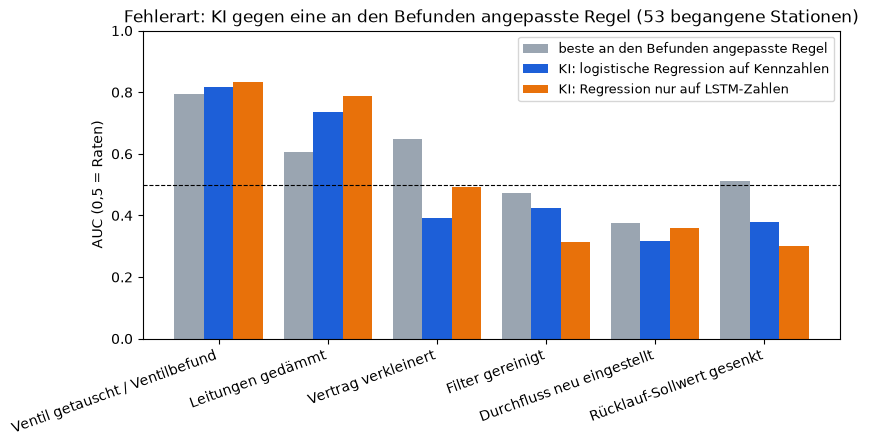

In [57]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(kg))
ax.bar(x - 0.27, kg["Regel angepasst"], 0.27, color="#9aa5b1", label="beste an den Befunden angepasste Regel")
ax.bar(x, kg["LR Kennzahlen"], 0.27, color="#1d5fd8", label="KI: logistische Regression auf Kennzahlen")
ax.bar(x + 0.27, kg["KI"], 0.27, color="#e8710a", label="KI: Regression nur auf LSTM-Zahlen")
ax.axhline(0.5, color="k", lw=0.8, ls="--")
ax.set_xticks(x, [fv.ZIEL_TEXT.get(z, z) for z in kg["Fehlerart"]], rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("AUC (0,5 = Raten)")
ax.set_title("Fehlerart: KI gegen eine an den Befunden angepasste Regel (53 begangene Stationen)")
ax.legend(loc="upper right", fontsize=9)
fv.speichere(fig, "13_ki_gegen_regel")
plt.show()

Bei der Dämmung kommt die beste Einzelregel auf 0,61, die Regression auf Kennzahlen auf 0,73 und das Dashboard-Modell auf 0,79. Die KI liegt um 0,18 [−0,03; +0,39] vorn, in 96 % der Ziehungen, knapp nicht gesichert. Das Muster steckt in der Kombination mehrerer Größen. Beim Ventil kommt die angepasste Regel (Nachtdurchfluss im Sommer) auf 0,79, die KI auf 0,83 (+0,04, in 65 % vorn, nicht gesichert). Die feste Sommernacht-Regel (0,85) ist sogar besser als die angepasste, Fachwissen schlägt also das Anpassen an 11 Fälle. Bei einem zu großen Anschluss scheitert die KI (0,49), weil ihr die Auslastung zum alten Vertrag fehlt, und die Regel aus Test C (0,76) bleibt. Bei Filter, Durchfluss und Temperatur kommen weder Regel noch KI über 0,51, die Information steckt nicht in den Zählerwerten.

### 14.2 Gleiche Methode, andere Kennzahlen

Die Regression bleibt gleich, nur die Kennzahlen ändern sich: die 5 Winterkennzahlen des Monitoring-Modells und Teilmengen der 12 Kennzahlen (`fv.merkmalssaetze_vergleich`).

In [58]:
netz15 = fv.netzvergleich(e["serien"], e["termine"], e["anschluss"], e["bhkw"])
mm15 = fv.monitoring_kennzahlen(netz15, "23/24").add_prefix("iv_")
sommer15 = ["sommer_nachtfluss_lph", "sommer_durchlauf_anteil", "sommer_nacht_spreizung_k", "sommerlast_anteil"]
winter15 = [k for k in fv.KENNZAHLEN if k not in sommer15]
X15 = kz15[fv.KENNZAHLEN].join(mm15)
saetze15 = {"LR 5 Winterkennzahlen des Monitoring-Modells": list(mm15.columns),
            "LR 8 Winterkennzahlen (Modell-Strang)": winter15,
            "LR 4 Sommerkennzahlen (Modell-Strang)": sommer15,
            "LR alle 12 Kennzahlen (Modell-Strang)": list(fv.KENNZAHLEN),
            "LR 12 + 5 des Monitoring-Modells": list(fv.KENNZAHLEN) + list(mm15.columns)}
ms = fv.merkmalssaetze_vergleich(X15, oof15, e["gruppen"], saetze15, ["ventil", "daemmung"])
ms[["Fehlerart", "Kennzahlen", "Anzahl", "AUC", "gefunden", "übersehen", "Fehlalarm"]].round(2)

,Fehlerart,Kennzahlen,Anzahl,AUC,gefunden,übersehen,Fehlalarm
0,ventil,LR 5 Winterkennzahlen des Monitoring-Modells,5,0.65,5,6,11
1,ventil,LR 8 Winterkennzahlen (Modell-Strang),8,0.74,6,5,10
2,ventil,LR 4 Sommerkennzahlen (Modell-Strang),4,0.92,8,3,3
3,ventil,LR alle 12 Kennzahlen (Modell-Strang),12,0.82,8,3,5
4,ventil,LR 12 + 5 des Monitoring-Modells,17,0.82,9,2,6
5,daemmung,LR 5 Winterkennzahlen des Monitoring-Modells,5,0.60,12,10,12
6,daemmung,LR 8 Winterkennzahlen (Modell-Strang),8,0.73,13,9,10
7,daemmung,LR 4 Sommerkennzahlen (Modell-Strang),4,0.57,10,12,9
8,daemmung,LR alle 12 Kennzahlen (Modell-Strang),12,0.73,14,8,7
9,daemmung,LR 12 + 5 des Monitoring-Modells,17,0.76,14,8,7


Beim Ventil entscheiden die Sommerkennzahlen (Winter 0,65 bis 0,74, 4 Sommerkennzahlen 0,92). Auf den Kennzahlen des Monitoring-Modells ist die Regression (0,65) nicht besser als dessen feste Regel (0,73). Der Vorsprung kommt also davon, was gemessen wird, nicht vom Lernen. Bei der Dämmung tragen die Winterkennzahlen (0,73), der Sommer allein nicht (0,57), und hier hilft Lernen auch auf den Kennzahlen des Monitoring-Modells (0,60 gegen 0,38). Mehr Kennzahlen sind nicht automatisch besser, beim Ventil verwässern Winterkennzahlen das Sommersignal (0,82 gegen 0,92). Die Sätze wurden nachträglich auf denselben 53 Stationen verglichen, 0,92 ist deshalb ein Hinweis, kein geprüfter Wert. Belastbar ist die Richtung, zu der auch die Sommernacht-Regel mit 0,85 passt.

### 14.3 Wächter zusammen

Kennlinie und Prognose-LSTM arbeiten hier zusammen auf den eingebauten Winterfehlern aus Test B. Gemeldet wird, sobald einer der beiden meldet (`fv.waechter_zusammen`).

In [59]:
faelle15 = pd.read_csv(fv.AUSGABE / "testB_faelle.csv")
wz = fv.waechter_zusammen(faelle15, "monitoring", "lstm_c", "Winter")
anzeige = wz.rename(columns={"monitoring": "Monitoring %", "lstm_c": "Prognose-LSTM %", "zusammen": "zusammen %"})
anzeige[["Monitoring %", "Prognose-LSTM %", "zusammen %"]] *= 100
anzeige.round(0)

key,Monitoring %,Prognose-LSTM %,zusammen %,Fälle
art,,,,
Dauerdurchfluss 150 l/h,78.0,69.0,87.0,77
Dauerdurchfluss 50 l/h,57.0,45.0,70.0,77
Fühler hängt,48.0,27.0,61.0,77
Regelhysterese 6 h,13.0,10.0,22.0,77
Rücklauf +5 K,56.0,25.0,65.0,77
ohne Fehler,12.0,3.0,12.0,77
schleichend +5 K in 30 Tagen,53.0,18.0,56.0,78


Im Winter ergänzt das Prognose-LSTM vor allem plötzliche Fehler: Dauerdurchfluss 50 l/h von 57 auf 70 %, Fühler hängt von 48 auf 61 % und Rücklauf +5 K von 56 auf 65 %. Bei langsamen Fehlern hilft es kaum (53 auf 56 %), über alle steigt die Quote von 51 auf 60 %. Die Fehlalarme bleiben bei 12 %, weil die LSTM-Fehlalarme in dieselben Fenster fallen. Gemessen ist das nur an eingebauten Fehlern. An echten Begehungen (Test A) meldet das LSTM nicht öfter als an Vergleichsstationen.

In [60]:
kg.to_csv(fv.AUSGABE / "ki_gegen_regel.csv", index=False)
regel15.to_csv(fv.AUSGABE / "ki_gegen_regel_vorhersagen.csv", index=False)
ms.to_csv(fv.AUSGABE / "kennzahlen_saetze.csv", index=False)
wz.to_csv(fv.AUSGABE / "waechter_zusammen.csv")
print("gespeichert in", fv.AUSGABE.relative_to(ROOT))

gespeichert in outputs/finalvergleich


Die KI bringt also dort etwas, wo eine einzelne Regel nicht reicht: bei der Dämmung mit einem Muster aus mehreren Kennzahlen, knapp nicht gesichert, und beim Wächter für plötzliche Sprünge, gemessen an eingebauten Fehlern. Beim Ventil ist eine Regel genauso gut. Bei sechs Fehlerarten und fünf Kennzahlensätzen kann ein einzelnes knappes Ergebnis auch Zufall sein.

## 15 Modellwahl ohne Blick auf die Testdaten

In Test C wurde jeder Kandidat sauber geprüft. Welcher Kandidat der beste ist, stand aber erst fest, nachdem die Testwerte bekannt waren, und so gewählt käme der beste beim Ventil auf 0,88. Diese Zahl ist zu optimistisch. Deshalb wird die Wahl hier selbst in die Kreuzvalidierung gelegt (`fv.modellwahl_verschachtelt`), mit denselben Durchgängen und Startwerten wie in Test C. In jedem Durchgang wird der Fingerabdruck ohne die Teststationen neu gelernt. Jeder der fünf Kandidaten wird nur im Lernteil bewertet, in einer inneren Kreuzvalidierung mit 4 Teilen. Der beste lernt dann auf allen Lernstationen und wird einmal auf die Teststationen angewendet. Bei Gleichstand gewinnt der einfachere. Gerechnet wird für Ventil und Dämmung.

In [61]:
oof16 = pd.read_csv(fv.AUSGABE / "testC_vorhersagen.csv")
mw = fv.modellwahl_verschachtelt(e, oof16, ["ventil", "daemmung"], log=print)
mw["wahl"].pivot(index="fold", columns="ziel", values="gewaehlt")

LSTM-Encoder: 88 Runden, bester Validierungsfehler 0.1708, 8 s


Durchgang 1 von 5 fertig


LSTM-Encoder: 85 Runden, bester Validierungsfehler 0.1617, 7 s


Durchgang 2 von 5 fertig


LSTM-Encoder: 87 Runden, bester Validierungsfehler 0.1935, 7 s


Durchgang 3 von 5 fertig


LSTM-Encoder: 73 Runden, bester Validierungsfehler 0.1845, 6 s


Durchgang 4 von 5 fertig


LSTM-Encoder: 84 Runden, bester Validierungsfehler 0.1374, 8 s


Durchgang 5 von 5 fertig


ziel,daemmung,ventil
fold,,
0,XGBoost Kennzahlen + LSTM,XGBoost Kennzahlen + LSTM
1,LR nur LSTM-Embedding,LR Kennzahlen + LSTM
2,LR Kennzahlen + LSTM,LR nur LSTM-Embedding
3,LR nur LSTM-Embedding,LR nur LSTM-Embedding
4,LR nur LSTM-Embedding,XGBoost Kennzahlen + LSTM


In [62]:
innen16 = mw["wahl"].set_index(["ziel", "fold"]).drop(columns="gewaehlt")
innen16.columns = [c.replace("AUC im Lernteil: ", "") for c in innen16.columns]
innen16.round(2)

,,LR Kennzahlen,LR Kennzahlen + LSTM,LR nur LSTM-Embedding,XGBoost Kennzahlen,XGBoost Kennzahlen + LSTM
ziel,fold,,,,,
ventil,0,0.81,0.86,0.91,0.66,0.94
daemmung,0,0.75,0.81,0.79,0.70,0.87
ventil,1,0.85,0.87,0.82,0.83,0.81
daemmung,1,0.66,0.76,0.79,0.60,0.73
ventil,2,0.73,0.81,0.82,0.71,0.72
daemmung,2,0.68,0.81,0.77,0.68,0.75
ventil,3,0.76,0.82,0.84,0.66,0.68
daemmung,3,0.61,0.68,0.71,0.59,0.60
ventil,4,0.84,0.85,0.81,0.77,0.88


Der Sieger wechselt je Durchgang. Beim Ventil gewinnt zweimal XGBoost mit LSTM, zweimal die Regression nur auf LSTM und einmal die Regression auf Kennzahlen und LSTM, bei der Dämmung dreimal die Regression nur auf LSTM. In jedem Durchgang gewinnt ein Kandidat mit LSTM-Zahlen, nie Kennzahlen allein, aber die Abstände sind oft nur wenige Hundertstel.

In [63]:
vgl16 = mw["oof"].merge(oof16[oof16["kandidat"] == fv.ENDMODELL][["zaehler", "ziel", "p"]]
                        .rename(columns={"p": "p_test_c"}), on=["zaehler", "ziel"])
abw16 = (vgl16["p_fest_nachgerechnet"] - vgl16["p_test_c"]).abs()
print(f"Abgleich mit Test C (feste Wahl {fv.ENDMODELL}, gleiche Folds und Startwerte):",
      f"größte Abweichung {abw16.max():.4f}, mittlere {abw16.mean():.4f}")

Abgleich mit Test C (feste Wahl LR nur LSTM-Embedding, gleiche Folds und Startwerte): größte Abweichung 0.0000, mittlere 0.0000


Die feste Wahl aus Test C wird genau nachgerechnet (Abweichung 0). Unterschiede in der nächsten Tabelle kommen also nur von der Modellwahl.

In [64]:
tab16 = fv.modellwahl_auswerten(mw, oof16, e["gruppen"])
tab16.round(2)

,Fehlerart,Verfahren,AUC,unten,oben,gefunden,übersehen,Fehlalarm,Befunde unter den ersten 10,gegen feste Wahl,Diff. unten,Diff. oben
0,ventil,Modellwahl im Lernteil (verschachtelt),0.84,0.68,0.97,8,3,5,8,0.00,-0.08,0.10
1,ventil,"LR nur LSTM-Embedding, fest gewählt (Test C)",0.83,0.64,0.98,8,3,4,7,NaN,NaN,NaN
2,ventil,Regel Sommernacht-Anteil (ohne Lernen),0.85,0.68,0.98,9,2,5,7,NaN,NaN,NaN
3,daemmung,Modellwahl im Lernteil (verschachtelt),0.78,0.64,0.91,15,7,6,9,-0.01,-0.10,0.09
4,daemmung,"LR nur LSTM-Embedding, fest gewählt (Test C)",0.79,0.65,0.90,15,7,7,9,NaN,NaN,NaN


Beim Ventil kommt die Wahl im Lernteil auf 0,84 [0,68; 0,97], mit 8 von 11 bei 5 Fehlalarmen und 8 unter den ersten 10. Das Dashboard-Modell allein liegt bei 0,83 (Unterschied +0,00 [−0,08; +0,10]). Die zuerst gewählte 0,88 war also um etwa 0,05 zu optimistisch. Mit der Sommernacht-Regel (0,85) liegt die KI gleichauf (−0,01 [−0,14; +0,12]). Bei der Dämmung kommt die Wahl auf 0,78 [0,64; 0,91], das Dashboard-Modell allein auf 0,79 (−0,01 [−0,10; +0,09]). Gegen die beste angepasste Regel (0,61) liegt sie um +0,17 [−0,04; +0,38] vorn, in 95 % der Ziehungen, knapp nicht gesichert. Für Aussagen gelten ab jetzt diese Zahlen, Ventil 0,84 und Dämmung 0,78.

In [65]:
mw["oof"].to_csv(fv.AUSGABE / "modellwahl_verschachtelt_vorhersagen.csv", index=False)
mw["wahl"].to_csv(fv.AUSGABE / "modellwahl_verschachtelt_wahl.csv", index=False)
tab16.to_csv(fv.AUSGABE / "modellwahl_verschachtelt.csv", index=False)
print("gespeichert in", fv.AUSGABE.relative_to(ROOT))

gespeichert in outputs/finalvergleich


### 15.1 Alle fünf Fehlerarten gegen die Regeln

Die Modellwahl im Lernteil läuft auch für Filter, Durchfluss und Sollwert. Danach treten alle fünf Fehlerarten gegen die angepasste Regel aus Abschnitt 14 an, auf gleichen Stationen, Folds und Ziehungen. Beim Ventil kommt die feste Sommernacht-Regel dazu, die dort die stärkere Regel ist.

In [66]:
mw3 = fv.modellwahl_verschachtelt(e, oof16, ["filter", "durchfluss", "temperatur"], log=print)
mw3["wahl"].pivot(index="fold", columns="ziel", values="gewaehlt")

LSTM-Encoder: 88 Runden, bester Validierungsfehler 0.1708, 8 s


Durchgang 1 von 5 fertig


LSTM-Encoder: 85 Runden, bester Validierungsfehler 0.1617, 7 s


Durchgang 2 von 5 fertig


LSTM-Encoder: 87 Runden, bester Validierungsfehler 0.1935, 7 s


Durchgang 3 von 5 fertig


LSTM-Encoder: 73 Runden, bester Validierungsfehler 0.1845, 6 s


Durchgang 4 von 5 fertig


LSTM-Encoder: 84 Runden, bester Validierungsfehler 0.1374, 8 s


Durchgang 5 von 5 fertig


ziel,durchfluss,filter,temperatur
fold,,,
0,XGBoost Kennzahlen + LSTM,LR Kennzahlen,LR Kennzahlen
1,XGBoost Kennzahlen + LSTM,XGBoost Kennzahlen,LR Kennzahlen
2,XGBoost Kennzahlen + LSTM,XGBoost Kennzahlen + LSTM,LR nur LSTM-Embedding
3,XGBoost Kennzahlen,LR nur LSTM-Embedding,XGBoost Kennzahlen
4,LR Kennzahlen,XGBoost Kennzahlen + LSTM,XGBoost Kennzahlen


Bei Filter, Durchfluss und Sollwert wechselt der Sieger noch stärker, und auch Kandidaten ohne LSTM-Zahlen gewinnen. Das passt dazu, dass es dort kein verlässliches Muster gibt.

In [67]:
ziele16 = ["ventil", "daemmung", "filter", "durchfluss", "temperatur"]
kz16 = fv.kennzahlen_vor_begehung(e["stunden"], e["labels"])
regel16 = fv.regel_angepasst(kz16, oof16, ziele16)
verschachtelt = pd.concat([mw["oof"], mw3["oof"]])
ki16 = verschachtelt[["zaehler", "fold", "ziel", "p", "y"]].assign(kandidat="KI mit Modellwahl im Lernteil")
kg16 = fv.ki_gegen_regel(pd.concat([oof16, ki16]), regel16, e["gruppen"], ziele16, ki="KI mit Modellwahl im Lernteil")
kg16 = kg16.rename(columns={"KI": "KI mit Modellwahl im Lernteil"})
kg16[["Fehlerart", "Befunde", "Regel angepasst", "LR Kennzahlen", "KI mit Modellwahl im Lernteil",
      "KI − Regel", "unten", "oben", "KI vorn in", "gesichert"]].round(2)

,Fehlerart,Befunde,Regel angepasst,LR Kennzahlen,KI mit Modellwahl im Lernteil,KI − Regel,unten,oben,KI vorn in,gesichert
0,ventil,11,0.79,0.82,0.84,0.04,-0.11,0.22,0.69,False
1,daemmung,22,0.61,0.73,0.78,0.17,-0.04,0.38,0.95,False
2,filter,25,0.47,0.43,0.39,-0.08,-0.25,0.09,0.18,False
3,durchfluss,18,0.38,0.32,0.37,-0.01,-0.22,0.19,0.45,False
4,temperatur,33,0.51,0.38,0.37,-0.15,-0.36,0.07,0.08,False


In [68]:
v = verschachtelt[verschachtelt["ziel"] == "ventil"].set_index("zaehler")
regel_fest = oof16[(oof16["ziel"] == "ventil") & (oof16["kandidat"] == "Regel Sommernacht-Anteil")].set_index("zaehler")["p"]
d, lo, hi = fv.bootstrap_auc_differenz(v["y"].to_numpy(), v["p"].to_numpy(), regel_fest.reindex(v.index).to_numpy(),
                                       e["gruppen"].reindex(v.index).to_numpy())
print(f"Ventil, KI mit Modellwahl im Lernteil gegen die feste Sommernacht-Regel: {d:+.2f} [{lo:+.2f}; {hi:+.2f}]")

Ventil, KI mit Modellwahl im Lernteil gegen die feste Sommernacht-Regel: -0.01 [-0.14; +0.12]


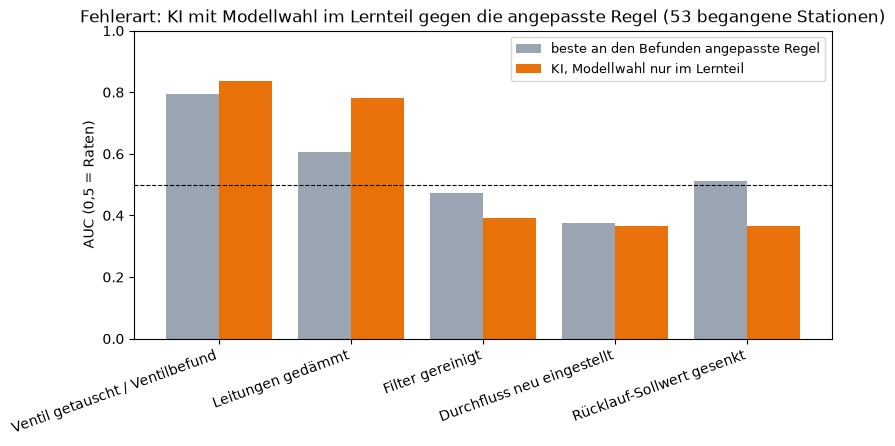

In [69]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(kg16))
ax.bar(x - 0.2, kg16["Regel angepasst"], 0.4, color="#9aa5b1", label="beste an den Befunden angepasste Regel")
ax.bar(x + 0.2, kg16["KI mit Modellwahl im Lernteil"], 0.4, color="#e8710a", label="KI, Modellwahl nur im Lernteil")
ax.axhline(0.5, color="k", lw=0.8, ls="--")
ax.set_xticks(x, [fv.ZIEL_TEXT.get(z, z) for z in kg16["Fehlerart"]], rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("AUC (0,5 = Raten)")
ax.set_title("Fehlerart: KI mit Modellwahl im Lernteil gegen die angepasste Regel (53 begangene Stationen)")
ax.legend(loc="upper right", fontsize=9)
fv.speichere(fig, "14_ki_gegen_regel_modellwahl")
plt.show()

Beim Ventil kommt die KI auf 0,84 gegen 0,79 für die angepasste Regel (+0,04 [−0,11; +0,22], in 69 % vorn), gegen die feste Sommernacht-Regel (0,85) liegt sie gleichauf (−0,01 [−0,14; +0,12]). Bei der Dämmung steht es 0,78 gegen 0,61, +0,17 [−0,04; +0,38], in 95 % vorn, knapp nicht gesichert. Bei Filter, Durchfluss und Sollwert kommt die KI auf 0,39, 0,37 und 0,37, die Regel auf 0,47, 0,38 und 0,51, keiner ist besser als Raten. Die Aussage aus Abschnitt 14 bleibt also, nur mit etwas kleineren, sauberen Zahlen.

In [70]:
mw3["oof"].to_csv(fv.AUSGABE / "modellwahl_verschachtelt_weitere_vorhersagen.csv", index=False)
mw3["wahl"].to_csv(fv.AUSGABE / "modellwahl_verschachtelt_weitere_wahl.csv", index=False)
kg16.to_csv(fv.AUSGABE / "ki_gegen_regel_modellwahl.csv", index=False)
print("gespeichert in", fv.AUSGABE.relative_to(ROOT))

gespeichert in outputs/finalvergleich


### 15.2 Welches Modell kommt ins Dashboard?

Auch diese Wahl schaut nicht auf die Testzahlen, nur auf die Validierung, also auf die AUC jedes Kandidaten in den inneren Teilen, gemittelt über die fünf Durchgänge.

In [71]:
wahl16 = pd.concat([mw["wahl"], mw3["wahl"]])
spalten = [c for c in wahl16.columns if c.startswith("AUC im Lernteil")]
innen_mittel = wahl16.groupby("ziel")[spalten].mean().T
innen_mittel.index = [i.replace("AUC im Lernteil: ", "") for i in innen_mittel.index]
innen_mittel[["ventil", "daemmung"]].round(2)

ziel,ventil,daemmung
LR Kennzahlen,0.80,0.67
LR Kennzahlen + LSTM,0.84,0.76
LR nur LSTM-Embedding,0.84,0.77
XGBoost Kennzahlen,0.73,0.63
XGBoost Kennzahlen + LSTM,0.81,0.73


Beim Ventil liegen die Regression nur auf LSTM-Zahlen und die auf Kennzahlen und LSTM gleichauf (beide 0,84), bei der Dämmung ebenfalls (0,77 und 0,76). XGBoost liegt dahinter und schwankt. Bei Gleichstand nimmt das Dashboard das einfachere Modell, die Regression nur auf den 16 LSTM-Zahlen (`fv.ENDMODELL`). Dazu kommt ein zweiter Grund: Die 12 Kennzahlen wurden festgelegt, als die Begehungsprotokolle schon bekannt waren, die LSTM-Zahlen sind dagegen ohne Befunde gelernt. Die Kennzahlen bleiben Begründung (Sommernacht) und Messlatte. Seine Testzahl aus Test C liegt beim Ventil bei 0,83 mit 8 von 11 bei 4 Fehlalarmen und bei der Dämmung bei 0,79 mit 15 von 22 bei 7 Fehlalarmen, nahe am sauberen Verfahren (0,84 und 0,78). Der Preis ist, dass es beim Ventil mit anderen Startwerten stärker schwankt (0,83 bis 0,90 gegen 0,88 bis 0,89) und sein Score nach einer Begehung auch ohne Ventiltausch sinkt (8.8).

## 16 Entscheidung

Jetzt liegen alle Ergebnisse vor. Die Tabelle fasst zusammen, welches Modell im Dashboard welche Aufgabe übernimmt und worauf das beruht.

| Aufgabe | im Dashboard | Beleg |
|---|---|---|
| Stationsleistung, Netzeffizienz, dauerhaft schlechter Betrieb | Monitoring-Modell: Netzvergleich je Kernwinter und Potenzial, rein beschreibend | Test D, Fall 1 |
| Veränderung in der Heizperiode, Erfolgskontrolle | Monitoring-Modell: Tagesmonitor mit h = 5 | Test A, B, Abschnitt 7.1 |
| Veränderung an warmen Tagen, plötzlicher Durchfluss | LSTM-Modell: Prognose-LSTM auf allen Stationen, CUSUM mit h = 10 | Test B, Abschnitt 7.2 |
| Fehlerart Ventil | LSTM-Modell: Ventil-Score aus der Regression nur auf den 16 LSTM-Zahlen, ohne Kennzahlen; das Fehlerbild „ventil“ des Monitoring-Modells hebt auf „hoch“ | Test C, E, Abschnitt 15 |
| Dämmung | LSTM-Modell, dieselbe Regression nur auf den LSTM-Zahlen, nur als Hinweis | Test C, Abschnitt 14, 15 |
| Kapazitätsanpassung | Regel Spitzenlast zum alten Vertrag | Test C |
| Regelungsoptimierung, Durchfluss, Sollwert, Filter, Regelhysterese | nicht als Fehlerart, höchstens als Symptom | Test B, C |
| echte Frühwarnung | nicht prüfbar | Abschnitt 1 |
| XGBoost, LSTM mit fester Referenz, Sommer-LSTM | nicht im Dashboard, kein Vorteil gegenüber dem Einfacheren | Test C, Abschnitt 7.1, 7.2 |

In der Heizperiode übernimmt das Monitoring-Modell, weil es Maßnahmen am deutlichsten bemerkt und im Winter eingebaute Fehler am besten findet. An warmen Tagen übernimmt das LSTM-Modell, weil nur es dort rechnet und das Wochenmittel bei wenigen Fehlalarmen schlägt. Beim Ventil gilt das LSTM-Modell mit dem Fehlerbild des Monitoring-Modells als Bestätigung, besser als die Sommernacht-Regel ist es aber nicht. Für Ventil und Dämmung rechnet das Dashboard nur mit den 16 LSTM-Zahlen, ohne die 12 Kennzahlen. In der Validierung liegen beide Varianten gleichauf (Ventil 0,84 und 0,84, Dämmung 0,77 und 0,76), die ohne Kennzahlen ist einfacher, und die Kennzahlen wurden in Kenntnis der Begehungsprotokolle festgelegt (Abschnitt 15.2). Die Kennzahlen bleiben trotzdem als Begründung im Hausfenster, etwa der Anteil der Sommernächte mit Durchfluss. Wo mit Befunden gelernt wird, bei der Fehlerart, zählen nur begangene Stationen, bei den Wächtern alle. Für Regelungsoptimierung und Frühwarnung reicht die Datenlage nicht, weil Befunde mit klarer Fehlerart und bekanntem Beginn fehlen.

### 16.1 Grenzen

Es gibt wenige Fälle, 43 Begehungen im Test sowie 11 Ventil- und 9 Vertragsfälle. Unterschiede unter etwa 0,1 AUC oder 5 Fällen sind nicht sichtbar, „nicht gesichert“ heißt also, dass die Daten nicht reichen. Bei vielen Gegenproben mit sieben Wächtern, drei Richtungen und zwei Vergleichsgruppen können einzelne kleine p-Werte Zufall sein. Entscheidend ist das gleiche Bild über Test A, Test B und die Kurven. Die Labels gelten nur für begangene Stationen, der Fehlerbeginn ist unbekannt, und die 37 nie begangenen Stationen sind unbekannt, nicht gesund. Die feste Referenz beim Monitoring-Modell lässt an 43 % der Testtage ein Konto am Deckel stehen, bei 31 von 81 Stationen mehr als die Hälfte der Zeit. Eingebaute Fehler zeigen, was ein Wächter grundsätzlich kann, nicht seine Trefferquote bei echten Fehlern. Die Probezeit ist klein (2.184 Stationstage), und die Arbeitslasten im Test liegen bei 2,7 bis 6,4 Alarmen je Station und Jahr. Die Rangfolge hängt laut Kurven kaum davon ab.

### 16.2 Warum andere Zahlen als in Notebook 34

| | Notebook 34 | hier |
|---|---|---|
| Schwellen | auf den Testfällen | Probezeit April/Mai, Bezug h = 5 des Monitoring-Modells |
| Referenz Monitoring-Modell | eigene Regel (endet kurz vor Begehung) | Kennlinie bis 31.01.2024, mit ihrer Streuungsregel |
| LSTM-Encoder | sah die Teststationen | je Fold neu, nur begangene; Gegenprobe alle |
| Merkmal Auslastung | dabei | entfernt |
| Begehungen | alle Alarme zusammen: Monitoring-Modell 33/43 | nach Richtung, Monitoring-Modell 18/43 (besser) |

## 17 So rechnet das Dashboard

Das Dashboard rechnet nichts selbst. Das Programm `python -m src.dashboard_daten` wendet die drei Pakete aus Abschnitt 13 auf die aktuellen Stundenreihen aus Notebook 00 an und schreibt die Ergebnisse nach `outputs/dashboard/`. Notebook 37 zeigt sie dann auf der Karte.

```
Stundenreihen aus Notebook 00
   │
   ├── normalmodell    (Monitoring-Modell)  →  Meldung an Heiztagen
   ├── prognose_lstm   (LSTM-Modell)        →  Meldung an warmen Tagen
   ├── fehlerklassen   (LSTM-Modell)        →  Ventil-Score, Dämmungs-Score, Hinweis Kapazität
   └── Netzvergleich   (Monitoring-Modell)  →  Rang im Netz, Fehlerbild, Potenzial
   │
   ▼
Empfehlung je Station: Handlung, Dringlichkeit, Reihenfolge
```

An jedem Tag kommt eine Meldung von genau einem Wächter. An Heiztagen ist das der Tagesmonitor des Monitoring-Modells, weil er in Test A die Begehungen am deutlichsten bemerkt und in Test B im Winter die meisten eingebauten Fehler findet. An warmen Tagen rechnet der Tagesmonitor nicht, dort übernimmt das Prognose-LSTM mit CUSUM (h = 10). Eine Meldung sagt nur, dass sich etwas verändert hat, nicht was.

Was zu tun ist, kommt aus dem Paket `fehlerklassen`. Das ist die logistische Regression auf den 16 LSTM-Zahlen aus Abschnitt 15.2, und sie gibt je Station einen Ventil- und einen Dämmungs-Score. Ab einem Ventil-Score von 0,5 ist die Klasse „Regelventil tauschen“, die Handlung ist dann eine Reparatur. Dazu kommen zwei Hinweise: „Dämmung prüfen“ ab einem Dämmungs-Score von 0,5 und „Kapazitätsanpassung prüfen“, wenn die Spitzenlast höchstens 69 % der Vertragsleistung erreicht.

Die Dringlichkeit ist eine feste Regel in `dashboard_daten.empfehlungen`:

| Dringlichkeit | wann | geprüft in Test C |
|---|---|---|
| hoch | Reparatur, und der Netzvergleich zeigt das Fehlerbild „ventil“ | 4 von 4 richtig |
| mittel | Reparatur nur nach dem Ventil-Score | 8 von 11 Ventilen gefunden, 4 Fehlalarme |
| niedrig | nur Hinweise: Kapazität, Dämmung oder Daten prüfen | – |
| keine | weder Handlung noch Hinweis | – |

Innerhalb einer Stufe wird nach dem Ventil-Score sortiert. In Test E hatten unter den ersten 10 nach diesem Score 7 einen Ventilbefund, Zufall wären etwa 2. Sonderfälle bekommen nur „Daten prüfen“. Das sind Stationen, deren Werte außerhalb dessen liegen, woraus das Modell gelernt hat, oder die keine typische Hausstation sind. Für sie ist der Score nicht geprüft.

Einiges fehlt bewusst, weil die Tests es nicht tragen. Notebook 34 hatte in Abschnitt 6.1 noch vorgeschlagen, nach Verschlechterungsalarmen und Potenzial zu sortieren und ab einem Score von 0,8 auf „hoch“ zu setzen. Vor Begehungen mit Befund gab es aber nicht mehr Alarme als bei den Kontrollen (Notebook 21), das Potenzial sagt nicht vorher, wo eine Begehung am meisten bringt (Test D), und die Grenze 0,8 ist nirgends geprüft. Auch Regelungsoptimierung empfiehlt das Dashboard nicht, weil kein Modell diese Maßnahme erkennt (Test C).

Im Hausfenster stehen Symptom, vermutete Ursache und dokumentierter Befund getrennt. Fehlt eine Voraussetzung, etwa ein Winter mit Stundenwerten, steht dort „nicht bewertbar“ mit dem Grund. Keine Meldung heißt also nie „in Ordnung“, und ein Score ist eine Rangfolge, keine Wahrscheinlichkeit.

## Zusammenfassung & Bewertung

**Ergebnis**

Keins der beiden Modelle ist allein besser. Das Monitoring-Modell übernimmt Heizperiode, Erfolgskontrolle und Netzvergleich, das LSTM-Modell die warmen Tage und die Fehlerart Ventil, mit dem Fehlerbild des Monitoring-Modells als Bestätigung. In Test A bemerkt das Monitoring-Modell 18 von 43 Begehungen als „besser“ gegen 24 % bei der Kontrolle (p = 0,006), das Prognose-LSTM liegt auf Höhe der Kontrolle. In Test B findet im Winter das Monitoring-Modell bei 10 % Fehlalarmen am meisten (Rücklauf +5 K 47 % gegen 33 %), im Sommer kann nur das LSTM prüfen (Dauerdurchfluss 150 l/h 78 % bei 5 % Fehlalarmen). Bei der Fehlerart mit Modellwahl im Lernteil kommt das Ventil auf 0,84 (Sommernacht-Regel 0,85) und die Dämmung auf 0,78 (beste Einzelregel 0,61), die Kapazität ist nur per Regel erkennbar (0,76). Für die Fehlerart nimmt das Dashboard die Regression nur auf den 16 LSTM-Zahlen, ohne Kennzahlen, weil sie in der Validierung gleichauf liegt und einfacher ist. Die drei Pakete `normalmodell`, `prognose_lstm` und `fehlerklassen` sind gespeichert, nachgeprüft und Betriebsversion des Dashboards (Notebook 37).

**Belastbar**

Alle Wächter haben gleiche Daten, Zeitachse und Alarmlast, Teststationen kommen nie ins Lernen, und die Unsicherheit ist über Stationen gerechnet. Der Vorteil des Monitoring-Modells kommt von der festen Referenz, denn ein gleich gebautes LSTM ist gleich gut (18 gegen 17 Prozentpunkte Vorsprung). Regelungsoptimierung, Durchfluss, Sollwert, Filter und Regelhysterese sind in den Zählerdaten nicht erkennbar. XGBoost und ein eigenes Sommer-LSTM bringen keinen Mehrwert.

**Schwach**

Es gibt wenige Fälle, 43 Begehungen sowie 11 Ventil- und 9 Vertragsfälle, und viele Vorsprünge sind nicht gesichert (Dämmung +0,17 [−0,04; +0,38]). Fall für Fall ist der Vorsprung des Monitoring-Modells gegen das LSTM nicht gesichert (p = 0,08 und 0,13), und mit nur begangenen Vergleichsstationen sinkt er (p = 0,17). Die Konten des Monitoring-Modells stehen an 43 % der Testtage am Deckel, und der Ventil-Score des Dashboard-Modells sinkt nach jeder Begehung, nicht nur nach einem Ventiltausch. Die Wirkung der Begehungen auf die Abkühlung (+0,82 kWh/m³) ist nicht gesichert (p = 0,37), und das Potenzial sagt die Wirkung kaum vorher.

**Offen**

Als Nächstes sollte die Referenz nach jeder Begehung und Heizperiode neu gelernt werden, danach sind Test A und B zu wiederholen. Ein prospektiver Test würde Stationen mit hohem Ventil-Score und Fehlerbild „ventil“ gezielt begehen. Echte Frühwarnung und Regelungsfehler bleiben nicht prüfbar, solange Befunde mit Fehlerbeginn und klarer Fehlerart fehlen (Fehler-Symptom-Matrix, Notebook 38). Fall 2, der Ventilbefund mit dem kleinsten Score, ist nur über seine Kennzahlen beschrieben. Warum beide Modelle ihn übersehen, ist ungeklärt. Offen ist auch, woran das Modell die Dämmung erkennt und warum Filter, Durchfluss und Sollwert gar nicht zu erkennen sind. Dem geht Notebook 36 nach.